In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/citrnminhtin/predict-students-dropout-and-academic-success/data.csv


In [3]:
import os, io, json, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, classification_report,
                             confusion_matrix)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
LABELS = ['Dropout', 'Enrolled', 'Graduate']
ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/mnt/data')
OUT = ROOT / 'rf_outputs'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (8,5), 'font.size': 10, 'axes.grid': False})
print('Output folder:', OUT)

Output folder: /kaggle/working/rf_outputs


In [4]:
DATA_PATH = Path('/kaggle/input/datasets/citrnminhtin/predict-students-dropout-and-academic-success/data.csv')

def load_dataset():
    # Dùng đúng đường dẫn Kaggle do bạn cung cấp, tránh đọc nhầm file CSV khác.
    if DATA_PATH.is_file():
        print('Loaded CSV:', DATA_PATH)
        return pd.read_csv(DATA_PATH, sep=';', encoding='utf-8-sig')
    print('Đường dẫn bạn gửi không có trong phiên này, đang tìm data.csv/ZIP dự phòng...')
    roots = [Path('/kaggle/input'), Path('/mnt/data')]
    files = []
    for root in roots:
        if root.exists():
            files.extend(p for p in root.rglob('*') if p.is_file() and p.suffix.lower() in ('.csv', '.zip'))
    csvs = sorted((p for p in files if p.name.lower() == 'data.csv'), key=lambda x: len(str(x)))
    if csvs:
        print('Loaded CSV:', csvs[0])
        return pd.read_csv(csvs[0], sep=';', encoding='utf-8-sig')
    for f in files:
        if f.suffix.lower() == '.zip':
            try:
                with zipfile.ZipFile(f) as z:
                    names = [n for n in z.namelist() if Path(n).name.lower() == 'data.csv']
                    if names:
                        print('Loaded ZIP:', f, 'member:', names[0])
                        return pd.read_csv(io.BytesIO(z.read(names[0])), sep=';', encoding='utf-8-sig')
            except (zipfile.BadZipFile, OSError):
                continue
    raise FileNotFoundError('Chưa tìm thấy data.csv hay ZIP chứa data.csv. Vào Kaggle → Add Input → Upload dataset.')

df = load_dataset()
df.columns = [c.strip() for c in df.columns]  # sửa tab trong tên cột gốc
assert 'Target' in df, 'Thiếu cột Target'
assert set(df['Target'].dropna().unique()) == set(LABELS), 'Target không đúng 3 lớp dự kiến'
print('Shape:', df.shape, '| Missing:', int(df.isna().sum().sum()), '| Duplicate:', int(df.duplicated().sum()))
print(df['Target'].value_counts().reindex(LABELS).to_string())
display(df.head())

Loaded CSV: /kaggle/input/datasets/citrnminhtin/predict-students-dropout-and-academic-success/data.csv
Shape: (4424, 37) | Missing: 0 | Duplicate: 0
Target
Dropout     1421
Enrolled     794
Graduate    2209


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


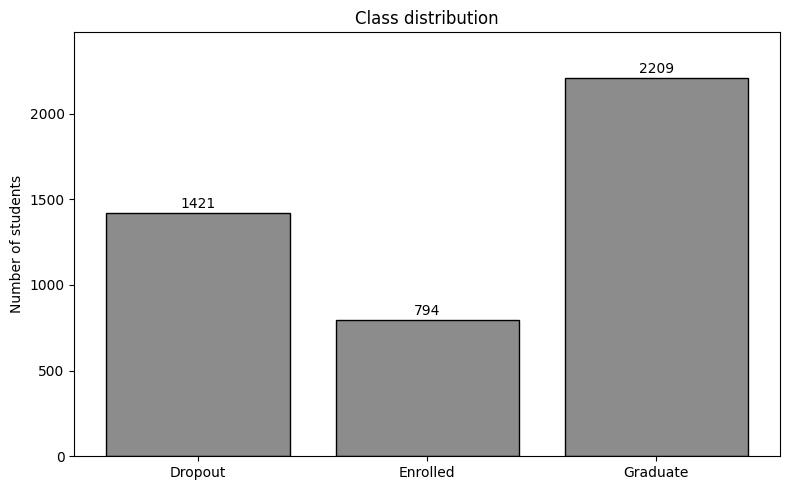

In [5]:
fig, ax = plt.subplots()
counts = df['Target'].value_counts().reindex(LABELS)
bars = ax.bar(counts.index, counts.values, color='0.55', edgecolor='black')
for b in bars:
    ax.text(b.get_x()+b.get_width()/2, b.get_height()+30, str(int(b.get_height())), ha='center')
ax.set(title='Class distribution', ylabel='Number of students', ylim=(0, max(counts)*1.12))
fig.tight_layout()
fig.savefig(OUT / '01_class_distribution.png', dpi=160)
plt.show()

In [6]:
CATEGORICAL_COLS = [
    'Marital status', 'Application mode', 'Course', 'Daytime/evening attendance',
    'Previous qualification', 'Nacionality', "Mother's qualification",
    "Father's qualification", "Mother's occupation", "Father's occupation",
    'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date',
    'Gender', 'Scholarship holder', 'International'
]
X = df.drop(columns='Target').copy()
y = df['Target'].copy()
assert all(c in X.columns for c in CATEGORICAL_COLS)
NUMERIC_COLS = [c for c in X.columns if c not in CATEGORICAL_COLS]

def make_preprocessor(columns):
    categorical = [c for c in CATEGORICAL_COLS if c in columns]
    numeric = [c for c in columns if c not in categorical]
    return ColumnTransformer([
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical),
        ('numeric', 'passthrough', numeric)
    ], remainder='drop')

def make_rf_pipe(columns, **rf_params):
    defaults = dict(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1)
    defaults.update(rf_params)
    return Pipeline([('prep',make_preprocessor(columns)),('rf',RandomForestClassifier(**defaults))])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Train label counts:\n',y_train.value_counts().reindex(LABELS).to_string())
print('Test label counts:\n',y_test.value_counts().reindex(LABELS).to_string())

Train: (3539, 36) Test: (885, 36)
Train label counts:
 Target
Dropout     1137
Enrolled     635
Graduate    1767
Test label counts:
 Target
Dropout     284
Enrolled    159
Graduate    442


In [7]:
def metric_row(model_name, y_true, y_pred):
    return dict(model=model_name, accuracy=accuracy_score(y_true, y_pred),
                balanced_accuracy=balanced_accuracy_score(y_true,y_pred),
                precision_macro=precision_score(y_true,y_pred,average='macro',zero_division=0),
                recall_macro=recall_score(y_true,y_pred,average='macro',zero_division=0),
                f1_macro=f1_score(y_true,y_pred,average='macro',zero_division=0),
                f1_weighted=f1_score(y_true,y_pred,average='weighted',zero_division=0),
                n_test=len(y_true))

def class_metric_frame(model_name, y_true, y_pred):
    report = classification_report(y_true, y_pred, labels=LABELS,
                                  output_dict=True, zero_division=0)
    return pd.DataFrame([
        {'model': model_name, 'class': cls, 'precision':report[cls]['precision'],
         'recall':report[cls]['recall'], 'f1':report[cls]['f1-score'],
         'support':int(report[cls]['support'])}
        for cls in LABELS
    ])

baseline = make_rf_pipe(X.columns)
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)
print('BASELINE\n', classification_report(y_test, pred_baseline, labels=LABELS, zero_division=0))

BASELINE
               precision    recall  f1-score   support

     Dropout       0.79      0.76      0.78       284
    Enrolled       0.58      0.26      0.36       159
    Graduate       0.77      0.94      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.66      0.66       885
weighted avg       0.74      0.76      0.74       885



In [8]:
param_dist = {
    'rf__n_estimators': [80, 100, 140],
    'rf__max_depth': [None, 12, 18],
    'rf__min_samples_leaf': [1, 2, 4],
    'rf__max_features': ['sqrt', 'log2'],
    'rf__class_weight': [None, 'balanced']
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    estimator=make_rf_pipe(X.columns), param_distributions=param_dist,
    n_iter=6, scoring='f1_macro', cv=cv, n_jobs=1,
    random_state=RANDOM_STATE, refit=True, return_train_score=True, verbose=1
)
search.fit(X_train, y_train)
tuned = search.best_estimator_
pred_tuned = tuned.predict(X_test)
print('Best CV Macro F1:', round(search.best_score_, 4))
print('Best params:', search.best_params_)
print('TUNED - HOLDOUT TEST\n', classification_report(y_test, pred_tuned, labels=LABELS, zero_division=0))
cv_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
display(cv_results[['rank_test_score','mean_test_score','std_test_score','mean_train_score','params']])

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best CV Macro F1: 0.7113
Best params: {'rf__n_estimators': 140, 'rf__min_samples_leaf': 4, 'rf__max_features': 'sqrt', 'rf__max_depth': None, 'rf__class_weight': 'balanced'}
TUNED - HOLDOUT TEST
               precision    recall  f1-score   support

     Dropout       0.80      0.72      0.76       284
    Enrolled       0.49      0.58      0.53       159
    Graduate       0.85      0.85      0.85       442

    accuracy                           0.76       885
   macro avg       0.71      0.72      0.71       885
weighted avg       0.77      0.76      0.76       885



,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
4,1,0.711280,0.020883,0.864313,"{'rf__n_estimators': 140, 'rf__min_samples_lea..."
0,2,0.709165,0.021347,0.882616,"{'rf__n_estimators': 140, 'rf__min_samples_lea..."
5,3,0.697651,0.020841,0.904274,"{'rf__n_estimators': 100, 'rf__min_samples_lea..."
3,4,0.697390,0.021193,0.900937,"{'rf__n_estimators': 140, 'rf__min_samples_lea..."
2,5,0.655975,0.008744,0.924967,"{'rf__n_estimators': 100, 'rf__min_samples_lea..."
1,6,0.648341,0.006821,1.000000,"{'rf__n_estimators': 100, 'rf__min_samples_lea..."


,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,n_test
0,RF_baseline,0.7616,0.6553,0.7133,0.6553,0.6621,0.7375,885
1,RF_tuned,0.7593,0.7176,0.7139,0.7176,0.7136,0.7636,885


,model,class,precision,recall,f1,support
0,RF_baseline,Dropout,0.7941,0.7606,0.7770,284
1,RF_baseline,Enrolled,0.5753,0.2642,0.3621,159
2,RF_baseline,Graduate,0.7704,0.9412,0.8473,442
3,RF_tuned,Dropout,0.8008,0.7218,0.7593,284
4,RF_tuned,Enrolled,0.4869,0.5849,0.5314,159
5,RF_tuned,Graduate,0.8539,0.8462,0.8500,442


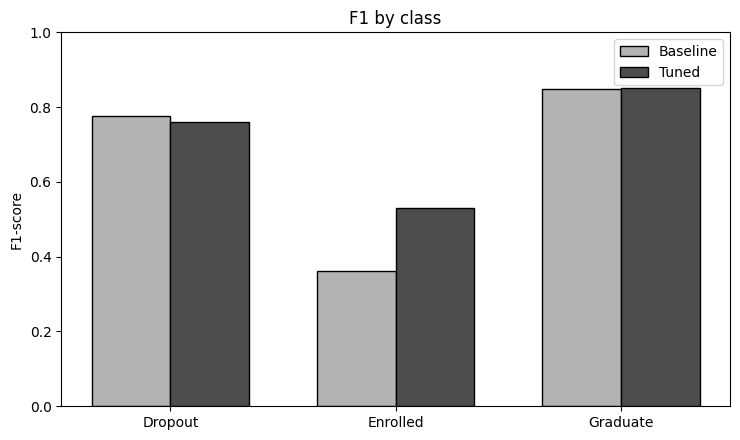

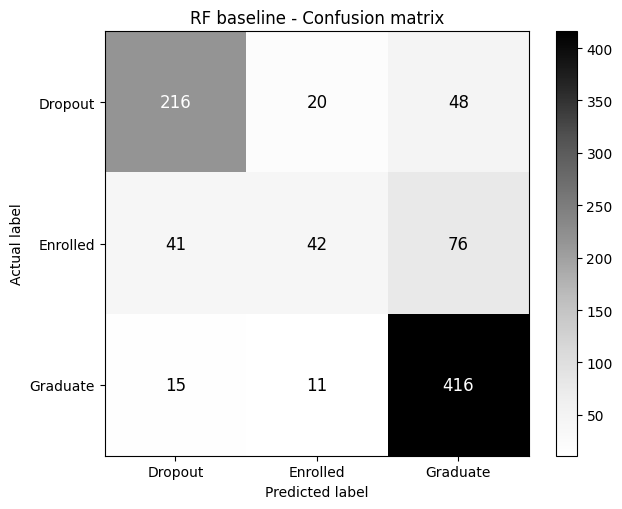

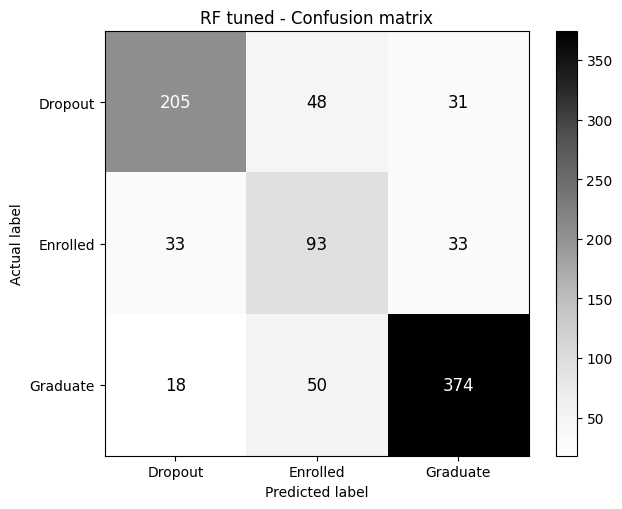

In [9]:
comparison = pd.DataFrame([
    metric_row('RF_baseline', y_test, pred_baseline),
    metric_row('RF_tuned', y_test, pred_tuned)
])
class_metrics = pd.concat([
    class_metric_frame('RF_baseline', y_test, pred_baseline),
    class_metric_frame('RF_tuned', y_test, pred_tuned)
], ignore_index=True)
display(comparison.round(4))
display(class_metrics.round(4))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
xx = np.arange(len(LABELS)); width=0.35
b=class_metrics.pivot(index='class', columns='model', values='f1').reindex(LABELS)
ax.bar(xx-width/2, b['RF_baseline'], width, label='Baseline', color='0.70', edgecolor='black')
ax.bar(xx+width/2, b['RF_tuned'], width, label='Tuned', color='0.30', edgecolor='black')
ax.set(xticks=xx, xticklabels=LABELS, ylim=(0,1), ylabel='F1-score',title='F1 by class')
ax.legend(); fig.tight_layout();fig.savefig(OUT/'02_class_f1_comparison.png',dpi=160);plt.show()

def plot_cm(y_true, y_pred, name, filename):
    cm=confusion_matrix(y_true,y_pred,labels=LABELS)
    fig,ax=plt.subplots(figsize=(6.4,5.2))
    im=ax.imshow(cm,cmap='Greys')
    ax.set(xticks=np.arange(3),yticks=np.arange(3),xticklabels=LABELS,yticklabels=LABELS,
           xlabel='Predicted label',ylabel='Actual label',title=name)
    for (i,j), val in np.ndenumerate(cm):
        ax.text(j,i,str(val),ha='center',va='center',
                color='white' if val>cm.max()/2 else 'black',fontsize=12)
    fig.colorbar(im,ax=ax,fraction=0.045)
    fig.tight_layout();fig.savefig(OUT/filename,dpi=160);plt.show()
    return cm
cm_baseline=plot_cm(y_test,pred_baseline,'RF baseline - Confusion matrix','03_cm_baseline.png')
cm_tuned=plot_cm(y_test,pred_tuned,'RF tuned - Confusion matrix','04_cm_tuned.png')

Errors: 213 / 885


,actual,predicted,count
5,Graduate,Enrolled,50
0,Dropout,Enrolled,48
3,Enrolled,Graduate,33
2,Enrolled,Dropout,33
1,Dropout,Graduate,31
4,Graduate,Dropout,18


,row_index,actual,predicted,confidence
278,278,Enrolled,Graduate,0.903646
1987,1987,Enrolled,Dropout,0.896352
3003,3003,Dropout,Graduate,0.873090
942,942,Enrolled,Dropout,0.850313
1618,1618,Dropout,Graduate,0.838328
3891,3891,Enrolled,Graduate,0.829080
2117,2117,Dropout,Graduate,0.820275
2126,2126,Dropout,Graduate,0.804111
1321,1321,Enrolled,Graduate,0.739246
2716,2716,Enrolled,Dropout,0.730638


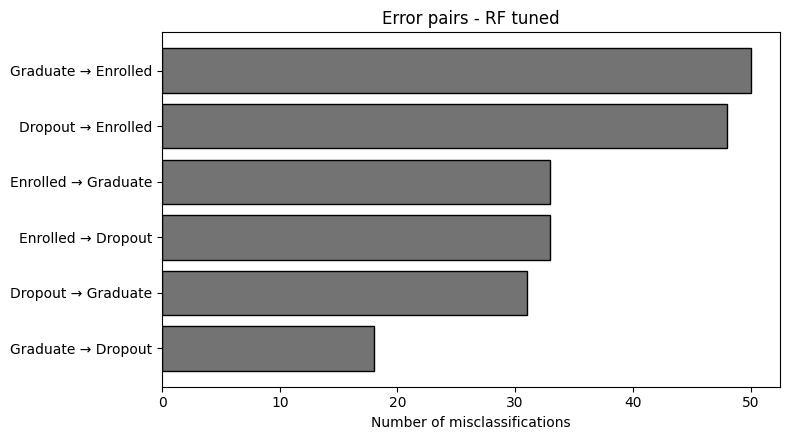

In [10]:
prob_tuned = tuned.predict_proba(X_test)
error_df=X_test.copy()
error_df.insert(0,'row_index', X_test.index)
error_df.insert(1,'actual',y_test.to_numpy())
error_df.insert(2,'predicted',pred_tuned)
error_df.insert(3,'confidence',prob_tuned.max(axis=1))
error_df.insert(4,'correct', error_df['actual']==error_df['predicted'])
error_pairs=(error_df.loc[~error_df['correct']].groupby(['actual','predicted'])
             .size().reset_index(name='count').sort_values('count',ascending=False))
print('Errors:', int((~error_df['correct']).sum()), '/', len(error_df))
display(error_pairs)
display(error_df.loc[~error_df['correct'],['row_index','actual','predicted','confidence']]
        .sort_values('confidence',ascending=False).head(12))
fig,ax=plt.subplots(figsize=(8,4.5))
error_pairs2=error_pairs.copy();error_pairs2['pair']=error_pairs2['actual']+' → '+error_pairs2['predicted']
ax.barh(error_pairs2['pair'][::-1],error_pairs2['count'][::-1],color='0.45',edgecolor='black')
ax.set(xlabel='Number of misclassifications',title='Error pairs - RF tuned')
fig.tight_layout();fig.savefig(OUT/'05_error_pairs.png',dpi=160);plt.show()

Stability macro F1: mean= 0.7196 std= 0.0139


,seed,accuracy,balanced_accuracy,f1_macro,f1_weighted
0,11,0.7751,0.7252,0.7285,0.7757
1,21,0.7582,0.7048,0.7078,0.7579
2,31,0.7785,0.7258,0.7294,0.7784
3,41,0.7819,0.7288,0.7307,0.7817
4,51,0.7537,0.6992,0.7014,0.7547


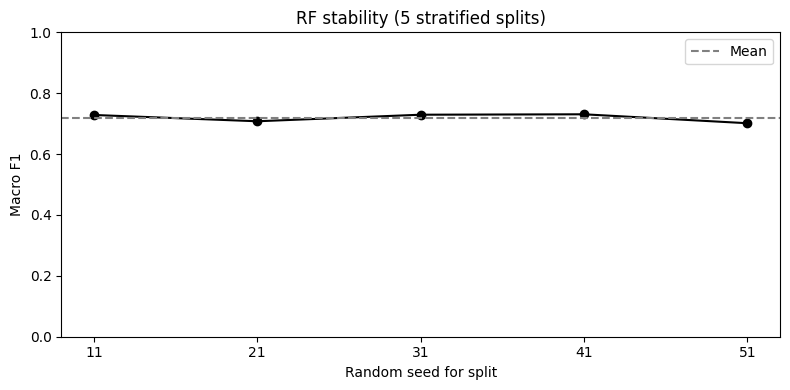

In [11]:
seed_list=[11,21,31,41,51]
stability_rows=[]
for seed in seed_list:
    xa,xb,ya,yb=train_test_split(X,y,test_size=0.2,stratify=y,random_state=seed)
    m=clone(tuned)
    m.set_params(rf__random_state=seed)
    m.fit(xa,ya)
    pred=m.predict(xb)
    stability_rows.append({'seed':seed,**metric_row('RF_tuned_stability',yb,pred)})
stability=pd.DataFrame(stability_rows)
print('Stability macro F1: mean=',round(stability.f1_macro.mean(),4),
      'std=',round(stability.f1_macro.std(ddof=1),4))
display(stability[['seed','accuracy','balanced_accuracy','f1_macro','f1_weighted']].round(4))
fig,ax=plt.subplots(figsize=(8,4))
ax.plot(stability['seed'].astype(str),stability['f1_macro'],marker='o',color='black')
ax.axhline(stability['f1_macro'].mean(),ls='--',color='0.5',label='Mean')
ax.set(xlabel='Random seed for split',ylabel='Macro F1',ylim=(0,1),title='RF stability (5 stratified splits)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'06_stability.png',dpi=160);plt.show()

,feature,permutation_mean,permutation_std,mdi_importance
0,Curricular units 2nd sem (approved),0.06749,0.01280,0.13479
1,Tuition fees up to date,0.05120,0.00035,0.06733
2,Curricular units 2nd sem (grade),0.03272,0.00024,0.10133
3,Curricular units 1st sem (approved),0.02893,0.00008,0.08119
4,Course,0.01713,0.00022,0.04305
5,Scholarship holder,0.01585,0.00373,0.02943
6,Curricular units 1st sem (evaluations),0.01347,0.00717,0.04610
7,Curricular units 2nd sem (evaluations),0.01200,0.00836,0.04234
8,Debtor,0.00936,0.00162,0.01687
9,Father's qualification,0.00816,0.00344,0.02072


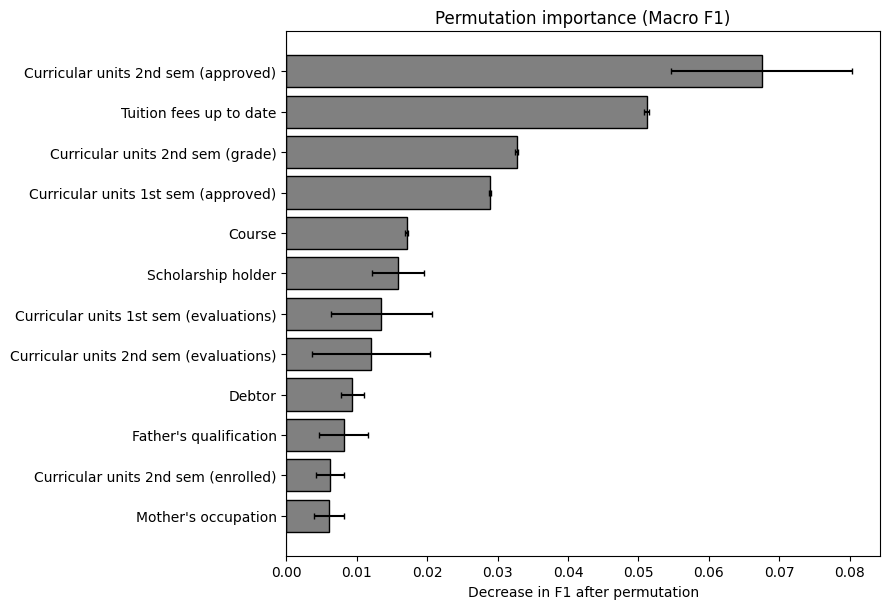

In [12]:
perm=permutation_importance(tuned,X_test,y_test,scoring='f1_macro',
                            n_repeats=2,random_state=RANDOM_STATE,n_jobs=1)
pre=tuned.named_steps['prep']
rf=tuned.named_steps['rf']
cat_map=[]
for c,categories in zip(CATEGORICAL_COLS,pre.named_transformers_['categorical'].categories_):
    cat_map.extend([c]*len(categories))
all_original_columns=cat_map+NUMERIC_COLS
assert len(all_original_columns)==len(rf.feature_importances_)
mdi_df=(pd.DataFrame({'feature':all_original_columns,'mdi_importance':rf.feature_importances_})
        .groupby('feature',as_index=False).sum())
importance=(pd.DataFrame({'feature':X.columns,
                          'permutation_mean':perm.importances_mean,
                          'permutation_std':perm.importances_std})
            .merge(mdi_df,on='feature',how='left')
            .sort_values('permutation_mean',ascending=False).reset_index(drop=True))
display(importance.head(15).round(5))
fig,ax=plt.subplots(figsize=(9,6.2))
top=importance.head(12).iloc[::-1]
ax.barh(top['feature'],top['permutation_mean'],xerr=top['permutation_std'],
        color='0.5',edgecolor='black',ecolor='black',capsize=2)
ax.axvline(0,color='black',lw=0.8)
ax.set(title='Permutation importance (Macro F1)',xlabel='Decrease in F1 after permutation')
fig.tight_layout();fig.savefig(OUT/'07_permutation_importance.png',dpi=160);plt.show()

In [13]:
EARLY_COLS=[c for c in X.columns if not c.startswith('Curricular units 1st sem')
            and not c.startswith('Curricular units 2nd sem')]
early=clone(tuned)
early.set_params(prep=make_preprocessor(EARLY_COLS))
early.fit(X_train[EARLY_COLS],y_train)
pred_early=early.predict(X_test[EARLY_COLS])
comparison=pd.concat([comparison,pd.DataFrame([
    metric_row('RF_enrollment_only_sensitivity',y_test,pred_early)])],ignore_index=True)
class_metrics=pd.concat([class_metrics,
    class_metric_frame('RF_enrollment_only_sensitivity',y_test,pred_early)],ignore_index=True)
print('Full features:',X.shape[1],'| Enrollment-only features:',len(EARLY_COLS))
display(comparison.round(4))

Full features: 36 | Enrollment-only features: 24


,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,n_test
0,RF_baseline,0.7616,0.6553,0.7133,0.6553,0.6621,0.7375,885
1,RF_tuned,0.7593,0.7176,0.7139,0.7176,0.7136,0.7636,885
2,RF_enrollment_only_sensitivity,0.6068,0.5616,0.5572,0.5616,0.5586,0.6113,885


In [14]:
# Export metrics & logs
comparison.to_csv(OUT/'experiment_log.csv',index=False,encoding='utf-8-sig')
class_metrics.to_csv(OUT/'class_metrics.csv',index=False,encoding='utf-8-sig')
cv_results[['rank_test_score','mean_test_score','std_test_score','mean_train_score','params']].to_csv(
    OUT/'tuning_cv_results.csv',index=False,encoding='utf-8-sig')
stability.to_csv(OUT/'stability_results.csv',index=False,encoding='utf-8-sig')
importance.to_csv(OUT/'feature_importance.csv',index=False,encoding='utf-8-sig')
error_pairs.to_csv(OUT/'error_pairs.csv',index=False,encoding='utf-8-sig')
error_df.to_csv(OUT/'error_cases.csv',index=False,encoding='utf-8-sig')
class_counts=df.Target.value_counts().reindex(LABELS).reset_index()
class_counts.columns=['class','count']
class_counts.to_csv(OUT/'class_distribution.csv',index=False,encoding='utf-8-sig')

# Template để điền kết quả mô hình khác (không tự bịa số liệu)
group_cols=['model','accuracy','balanced_accuracy','precision_macro','recall_macro','f1_macro','f1_weighted','n_test']
comparison[group_cols].to_csv(OUT/'group_comparison_template.csv',index=False,encoding='utf-8-sig')

r_base=comparison.set_index('model').loc['RF_baseline']
r_tuned=comparison.set_index('model').loc['RF_tuned']
r_early=comparison.set_index('model').loc['RF_enrollment_only_sensitivity']
cm=cm_tuned
errors=int((~error_df['correct']).sum())
major_error=error_pairs.iloc[0] if len(error_pairs) else None
f1t=class_metrics[class_metrics.model=='RF_tuned'].set_index('class')
important=importance.head(5)['feature'].tolist()
params=json.dumps(search.best_params_,ensure_ascii=False,indent=2,default=str)
summary={
  'n_rows':len(df),'n_features':X.shape[1],'target_counts':counts.to_dict(),
  'n_train':len(X_train),'n_test':len(X_test),
  'best_cv_f1_macro':float(search.best_score_), 'best_params':search.best_params_,
  'test_baseline':{k:float(r_base[k]) for k in ['accuracy','balanced_accuracy','f1_macro','f1_weighted']},
  'test_tuned':{k:float(r_tuned[k]) for k in ['accuracy','balanced_accuracy','f1_macro','f1_weighted']},
  'test_early_features':{k:float(r_early[k]) for k in ['accuracy','balanced_accuracy','f1_macro','f1_weighted']},
  'stability_mean_f1_macro':float(stability.f1_macro.mean()),
  'stability_std_f1_macro':float(stability.f1_macro.std(ddof=1)),
  'error_count':errors,'confusion_matrix_order':LABELS,'confusion_matrix':cm.tolist(),
  'top5_permutation_features':important,
  'class_f1':{lab:float(f1t.loc[lab,'f1']) for lab in LABELS}
}
(OUT/'report_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str),encoding='utf-8')

major_error_text=(f"{major_error['actual']} → {major_error['predicted']} ({int(major_error['count'])} mẫu)"
                  if major_error is not None else 'Không có lỗi')
notes=f"""# GỢI Ý BÁO CÁO — RANDOM FOREST (số liệu sinh tự động từ notebook)

## 2.4. Mô hình Random Forest
Random Forest là mô hình học máy tổ hợp sử dụng nhiều cây quyết định. Mỗi cây được xây dựng từ mẫu bootstrap của tập huấn luyện, và tại từng nút chỉ xét một tập con đặc trưng để giảm tương quan giữa các cây. Khi phân loại, các cây cùng bỏ phiếu cho lớp dự đoán. Ưu điểm: khai thác quan hệ phi tuyến, ít cần chuẩn hóa, xử lý nhiều loại biến; nhược điểm: khó giải thích từng quyết định, có thể thiên về lớp đông và phụ thuộc vào thời điểm có dữ liệu. Với các biến mã danh mục, dùng One-Hot Encoding thay vì coi mã số là khoảng cách định lượng.

## 4.3. Thực nghiệm Random Forest
Dữ liệu gồm {len(df):,} sinh viên, {X.shape[1]} đặc trưng và 3 nhãn: Dropout={int(counts['Dropout'])}, Enrolled={int(counts['Enrolled'])}, Graduate={int(counts['Graduate'])}. Tập train={len(X_train)}, test={len(X_test)} (80/20; stratify; seed=42). Mô hình baseline dùng n_estimators=100; mô hình tuning sử dụng RandomizedSearchCV 6 tổ hợp, 3-fold CV, chọn bằng Macro F1 trên tập train.

Tham số tối ưu: {params}
CV Macro F1 tốt nhất: {search.best_score_:.4f}.

Trên test, baseline: Accuracy={r_base['accuracy']:.4f}, Macro F1={r_base['f1_macro']:.4f}, Balanced Accuracy={r_base['balanced_accuracy']:.4f}. RF tuned: Accuracy={r_tuned['accuracy']:.4f}, Macro F1={r_tuned['f1_macro']:.4f}, Balanced Accuracy={r_tuned['balanced_accuracy']:.4f}.

F1 từng lớp của RF tuned: Dropout={f1t.loc['Dropout','f1']:.4f}, Enrolled={f1t.loc['Enrolled','f1']:.4f}, Graduate={f1t.loc['Graduate','f1']:.4f}. Đánh giá không chỉ dựa trên Accuracy vì số lượng lớp không cân bằng.

## 4.5. Phân tích lỗi và độ ổn định
RF tuned phân loại sai {errors}/{len(X_test)} mẫu test. Cặp nhầm lẫn phổ biến nhất: {major_error_text}. Ma trận nhầm lẫn (hàng = thực tế, cột = dự đoán, thứ tự Dropout/Enrolled/Graduate): {cm.tolist()}. Dựa vào bảng class_metrics.csv để phân tích Precision/Recall và rủi ro bỏ sót Dropout, nhất là các trường hợp model dự đoán Graduate hoặc Enrolled.

Qua 5 lần chia 80/20 theo random seed khác nhau (không tuning lại), Macro F1 trung bình={stability.f1_macro.mean():.4f}, độ lệch chuẩn mẫu={stability.f1_macro.std(ddof=1):.4f}. Đây là độ ổn định theo cách chia tập dữ liệu, không chứng minh hiệu quả khi đưa vào trường khác hoặc năm khác.

5 đặc trưng nổi bật theo Permutation Importance (Macro F1): {', '.join(important)}. Tầm quan trọng dự đoán không đồng nghĩa quan hệ nhân quả; với biến tương quan, điểm importance có thể nhỏ hơn tác động thực tế.

## 4.4. So sánh mô hình (dành cho nhóm)
Dùng experiment_log.csv và group_comparison_template.csv. Chỉ điền kết quả của thành viên khác sau khi xác nhận cùng split, random_state, metric, cùng tập test, và chuẩn xử lý. Nếu không cùng protocol thì ghi rõ là so sánh tham khảo, không kết luận mô hình nào vượt trội.

## Chương 5. Hạn chế và hướng tiếp theo
Dữ liệu từ một bối cảnh giáo dục cụ thể và có mất cân bằng nhãn; mô hình có thể không khái quát sang cơ sở khác. Dữ liệu học kỳ 1 và 2 không có ngay khi nhập học, nên không thể dùng mô hình đầy đủ để cảnh báo sớm ngay ngày đầu tiên. Trong thí nghiệm độ nhạy chỉ dùng dữ liệu trước/khi nhập học ({len(EARLY_COLS)} đặc trưng), Macro F1={r_early['f1_macro']:.4f} so với {r_tuned['f1_macro']:.4f} của mô hình đầy đủ; đây không phải đối chứng công bằng tuyệt đối vì chưa tuning lại mô hình đầu vào nhập học. Đề xuất: thu thập dữ liệu đa trường/năm, đánh giá theo thời gian, thử class_weight/sampling trong train, hiệu chỉnh xác suất, kiểm tra độ công bằng và triển khai cảnh báo có con người giám sát.

## Chương 6. Đóng góp, khó khăn và kế hoạch cá nhân (cần tự chỉnh để đúng công việc thực tế)
**Đóng góp đã được notebook này minh chứng:** xây dựng RF baseline/tuning, xuất log metric và class metrics, confusion matrix, phân tích lỗi, kiểm tra ổn định 5 lần chia, feature importance, viết diễn giải dựa trên số liệu. **Chỉ ghi nhận những công việc bạn thực sự đã tự làm** (đính kèm link notebook Kaggle và ảnh lịch sử chạy/version).
**Khó khăn tham khảo:** mất cân bằng nhãn; thời gian tìm tham số; hiểu đúng ý nghĩa các đặc trưng mã hóa và chỉ số Macro F1; so sánh với nhóm cần thống nhất protocol.
**Kế hoạch:** thống nhất bảng 4.4 với nhóm; kiểm tra chéo log; hoàn thiện Word, minh chứng và chuyển sang slide từ bản Word được chốt.

**Nguồn dữ liệu:** UCI Machine Learning Repository, Predict Students' Dropout and Academic Success, https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success
"""
(OUT/'rf_report_notes_vi.md').write_text(notes,encoding='utf-8')

import shutil
zip_path=ROOT/'RF_Kaggle_Outputs.zip'
if zip_path.exists(): zip_path.unlink()
shutil.make_archive(str(zip_path.with_suffix('')),'zip',OUT)
print('Đã xuất',len(list(OUT.iterdir())),'files tại',OUT)
print('ZIP:', zip_path, 'size:',round(zip_path.stat().st_size/1024,1),'KB')
print('RANDOM FOREST COMPLETE')

Đã xuất 18 files tại /kaggle/working/rf_outputs
ZIP: /kaggle/working/RF_Kaggle_Outputs.zip size: 281.1 KB
RANDOM FOREST COMPLETE


In [15]:
import io, json, hashlib, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import __version__ as SKLEARN_VERSION
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, classification_report, confusion_matrix, brier_score_loss
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
LABELS = ['Dropout','Enrolled','Graduate']
DATA_PATH = Path('/kaggle/input/datasets/citrnminhtin/predict-students-dropout-and-academic-success/data.csv')
FAST_MODE = True     # True: 8 tổ hợp + 5 lần kiểm tra ổn định; False: 12 tổ hợp + 8 lần
N_ITER = 8 if FAST_MODE else 12
STABILITY_SEEDS = [11,21,31,41,51] if FAST_MODE else [11,21,31,41,51,61,71,81]
PERM_REPEATS = 2 if FAST_MODE else 4
PERM_MAX_SAMPLES = 300 if FAST_MODE else 500
ROOT = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path('/mnt/data')
OUT = ROOT / 'RF_Advanced_Outputs'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize':(8,5), 'font.size':10, 'axes.grid':False})
print('scikit-learn:', SKLEARN_VERSION, '| FAST_MODE:', FAST_MODE, '| output:', OUT)

scikit-learn: 1.6.1 | FAST_MODE: True | output: /kaggle/working/RF_Advanced_Outputs


SOURCE: /kaggle/input/datasets/citrnminhtin/predict-students-dropout-and-academic-success/data.csv | SHAPE: (4424, 37)
Missing cells: 0 | Duplicate rows: 0
Class counts:
 Target
Dropout     1421
Enrolled     794
Graduate    2209
Name: count, dtype: int64
SHA256: 3ef126de5cefff26eb11fbb4237f1a1401cb64b488e2f1d598c23cedeb4c45ae


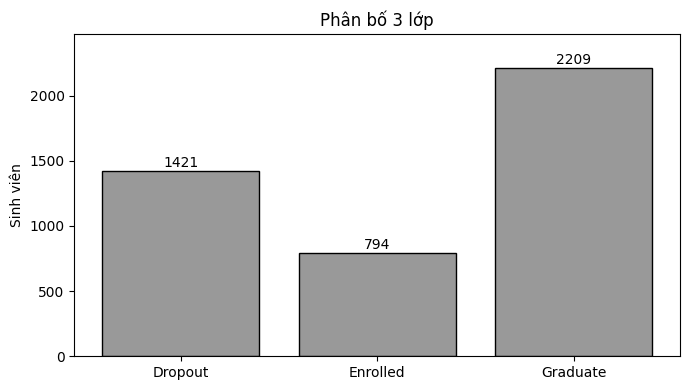

In [16]:
def load_source():
    if DATA_PATH.is_file():
        raw = DATA_PATH.read_bytes()
        return pd.read_csv(io.BytesIO(raw),sep=';',encoding='utf-8-sig'), raw, str(DATA_PATH)
    local_csv = Path('/mnt/data/data.csv')
    if local_csv.is_file():
        raw = local_csv.read_bytes()
        return pd.read_csv(io.BytesIO(raw),sep=';',encoding='utf-8-sig'), raw, str(local_csv)
    for zpath in [Path('/mnt/data/predict+students+dropout+and+academic+success.zip')]:
        if zpath.is_file():
            with zipfile.ZipFile(zpath) as z:
                name = next((n for n in z.namelist() if Path(n).name.lower()=='data.csv'),None)
                if name:
                    raw = z.read(name)
                    return pd.read_csv(io.BytesIO(raw),sep=';',encoding='utf-8-sig'),raw,f'{zpath}:{name}'
    raise FileNotFoundError('Chưa thấy data.csv. Trên Kaggle chọn Add Input và kiểm tra lại DATA_PATH.')

df, source_bytes, data_source=load_source()
df.columns=[x.strip() for x in df.columns]
assert df.shape[1]==37 and 'Target' in df.columns, f'Dữ liệu không đúng schema dự kiến: {df.shape}'
assert set(df.Target.unique())==set(LABELS), 'Nhãn Target không khớp'
print('SOURCE:',data_source,'| SHAPE:',df.shape)
print('Missing cells:',int(df.isna().sum().sum()),'| Duplicate rows:',int(df.duplicated().sum()))
print('Class counts:\n',df.Target.value_counts().reindex(LABELS))
source_sha=hashlib.sha256(source_bytes).hexdigest()
print('SHA256:',source_sha)
counts=df.Target.value_counts().reindex(LABELS)
fig,ax=plt.subplots(figsize=(7,4))
bars=ax.bar(counts.index,counts.values,color='0.6',edgecolor='black')
for b in bars:
    ax.text(b.get_x()+b.get_width()/2,b.get_height()+30,f'{int(b.get_height())}',ha='center')
ax.set(ylabel='Sinh viên',title='Phân bố 3 lớp',ylim=(0,int(counts.max()*1.12)))
fig.tight_layout();fig.savefig(OUT/'01_class_distribution.png',dpi=150);plt.show()

In [17]:
CATEGORICAL=[
    'Marital status','Application mode','Course','Daytime/evening attendance',
    'Previous qualification','Nacionality',"Mother's qualification","Father's qualification",
    "Mother's occupation","Father's occupation",'Displaced','Educational special needs',
    'Debtor','Tuition fees up to date','Gender','Scholarship holder','International'
]
X = df.drop(columns=['Target']).copy()
y = df['Target'].copy()
assert all(c in X.columns for c in CATEGORICAL), 'Thiếu cột danh mục; hãy kiểm tra schema'
X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.20,stratify=y,random_state=SEED)

pd.DataFrame({'row_index':X_test.index,'Target':y_test.values}).to_csv(
    OUT/'test_indices.csv',index=False,encoding='utf-8-sig')

def preprocessor(columns):
    categorical=[c for c in columns if c in CATEGORICAL]
    numeric=[c for c in columns if c not in categorical]
    return ColumnTransformer([
        ('categorical',OneHotEncoder(handle_unknown='ignore',sparse_output=False),categorical),
        ('numeric','passthrough',numeric)
    ],remainder='drop')

def pipe(columns, **params):
    default={'n_estimators':120,'random_state':SEED,'n_jobs':1}
    default.update(params)
    return Pipeline([('prep',preprocessor(list(columns))),
                     ('rf',RandomForestClassifier(**default))])

def metric_row(name, truth, preds, stage='holdout', features='full',cv_mean=np.nan):
    return {'model':name,'stage':stage,'features':features,'accuracy':accuracy_score(truth,preds),
            'balanced_accuracy':balanced_accuracy_score(truth,preds),
            'precision_macro':precision_score(truth,preds,average='macro',zero_division=0),
            'recall_macro':recall_score(truth,preds,average='macro',zero_division=0),
            'f1_macro':f1_score(truth,preds,average='macro',zero_division=0),
            'f1_weighted':f1_score(truth,preds,average='weighted',zero_division=0),
            'dropout_precision':precision_score(truth,preds,labels=['Dropout'],average='macro',zero_division=0),
            'dropout_recall':recall_score(truth,preds,labels=['Dropout'],average='macro',zero_division=0),
            'n_test':len(truth),'split_seed':SEED,'test_fraction':0.2,'train_cv_f1_macro':cv_mean}

def class_table(name, truth, preds):
    report=classification_report(truth,preds,labels=LABELS,output_dict=True,zero_division=0)
    return pd.DataFrame([{'model':name,'class':label,'precision':report[label]['precision'],
                'recall':report[label]['recall'],'f1':report[label]['f1-score'],
                'support':int(report[label]['support'])} for label in LABELS])

print('TRAIN:',X_train.shape,'TEST:',X_test.shape)
print('TEST DISTRIBUTION:',y_test.value_counts().reindex(LABELS).to_dict())

TRAIN: (3539, 36) TEST: (885, 36)
TEST DISTRIBUTION: {'Dropout': 284, 'Enrolled': 159, 'Graduate': 442}


In [18]:
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
base=pipe(X_train.columns)
base.fit(X_train,y_train)

param_grid={
    'rf__n_estimators':[100,150,200],
    'rf__max_depth':[None,12,20],
    'rf__min_samples_leaf':[1,2,4],
    'rf__max_features':['sqrt','log2'],
    'rf__class_weight':[None,'balanced','balanced_subsample']
}
search=RandomizedSearchCV(
    pipe(X_train.columns),param_distributions=param_grid,n_iter=N_ITER,
    scoring='f1_macro',cv=cv,random_state=SEED,n_jobs=1,
    refit=True,return_train_score=True,verbose=1)
search.fit(X_train,y_train)
tuned=search.best_estimator_
cv_results=pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
print('BEST CV MACRO F1:',round(search.best_score_,4))
print('BEST PARAMS:',search.best_params_)
display(cv_results[['rank_test_score','mean_test_score','std_test_score','mean_train_score','params']].round(4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
BEST CV MACRO F1: 0.7103
BEST PARAMS: {'rf__n_estimators': 200, 'rf__min_samples_leaf': 2, 'rf__max_features': 'sqrt', 'rf__max_depth': 12, 'rf__class_weight': 'balanced_subsample'}


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
2,1,0.7103,0.0225,0.8805,"{'rf__n_estimators': 200, 'rf__min_samples_lea..."
4,2,0.7056,0.0266,0.9573,"{'rf__n_estimators': 150, 'rf__min_samples_lea..."
0,3,0.6981,0.0186,0.9023,"{'rf__n_estimators': 200, 'rf__min_samples_lea..."
6,4,0.6780,0.0176,0.9933,"{'rf__n_estimators': 200, 'rf__min_samples_lea..."
1,5,0.6748,0.0046,1.0000,"{'rf__n_estimators': 150, 'rf__min_samples_lea..."
3,6,0.6708,0.0064,1.0000,"{'rf__n_estimators': 150, 'rf__min_samples_lea..."
5,7,0.5922,0.0153,0.8366,"{'rf__n_estimators': 200, 'rf__min_samples_lea..."
7,8,0.5722,0.0124,0.6848,"{'rf__n_estimators': 100, 'rf__min_samples_lea..."


In [19]:
def add_academic_features(data):
    z=data.copy()
    for s in ['1st','2nd']:
        prefix=f'Curricular units {s} sem'
        enrolled=z[f'{prefix} (enrolled)'].astype(float)
        approved=z[f'{prefix} (approved)'].astype(float)
        evaluated=z[f'{prefix} (evaluations)'].astype(float)
        z[f'{s}_approval_per_enrolled']=approved / enrolled.where(enrolled>0, np.nan)
        z[f'{s}_approval_per_enrolled']=z[f'{s}_approval_per_enrolled'].fillna(0)
        z[f'{s}_approval_per_evaluation']=approved / evaluated.where(evaluated>0, np.nan)
        z[f'{s}_approval_per_evaluation']=z[f'{s}_approval_per_evaluation'].fillna(0)
        z[f'{s}_not_approved_count']=(enrolled-approved).clip(lower=0)
    z['grade_change_sem2_minus_sem1']=(z['Curricular units 2nd sem (grade)']-
                                        z['Curricular units 1st sem (grade)'])
    z['approved_change_sem2_minus_sem1']=(z['Curricular units 2nd sem (approved)']-
                                           z['Curricular units 1st sem (approved)'])
    return z

X_train_eng=add_academic_features(X_train)
X_test_eng=add_academic_features(X_test)
engineered=pipe(X_train_eng.columns)
engineered.set_params(**search.best_params_)
original_cv=cross_val_score(clone(tuned),X_train,y_train,scoring='f1_macro',cv=cv,n_jobs=1)
engineered_cv=cross_val_score(clone(engineered),X_train_eng,y_train,scoring='f1_macro',cv=cv,n_jobs=1)
selection=pd.DataFrame([
    {'candidate':'RF_tuned','cv_macro_f1_mean':original_cv.mean(),'cv_macro_f1_std':original_cv.std(ddof=1)},
    {'candidate':'RF_engineered','cv_macro_f1_mean':engineered_cv.mean(),'cv_macro_f1_std':engineered_cv.std(ddof=1)}
]).sort_values('cv_macro_f1_mean',ascending=False)
engineered.fit(X_train_eng,y_train)
champion_name=selection.iloc[0]['candidate']
champion=tuned if champion_name=='RF_tuned' else engineered
train_champion=X_train if champion_name=='RF_tuned' else X_train_eng
test_champion=X_test if champion_name=='RF_tuned' else X_test_eng
print('TRAIN-only model choice:',champion_name)
display(selection.round(4))

TRAIN-only model choice: RF_engineered


,candidate,cv_macro_f1_mean,cv_macro_f1_std
1,RF_engineered,0.7209,0.0231
0,RF_tuned,0.7103,0.0275


Champion by TRAIN CV: RF_engineered


,model,stage,features,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,dropout_precision,dropout_recall,n_test,split_seed,test_fraction,train_cv_f1_macro
0,RF_baseline,holdout,full,0.7684,0.6651,0.7282,0.6651,0.6734,0.7456,0.7906,0.7711,885,42,0.2,NaN
1,RF_tuned,holdout,full,0.7537,0.7091,0.7093,0.7091,0.7057,0.7591,0.8197,0.7042,885,42,0.2,0.7103
2,RF_engineered,holdout,full+derived,0.7593,0.7167,0.7172,0.7167,0.7138,0.7645,0.8374,0.7254,885,42,0.2,0.7209


,model,class,precision,recall,f1,support
0,RF_baseline,Dropout,0.7906,0.7711,0.7807,284
1,RF_baseline,Enrolled,0.6164,0.2830,0.3879,159
2,RF_baseline,Graduate,0.7776,0.9412,0.8516,442
3,RF_tuned,Dropout,0.8197,0.7042,0.7576,284
4,RF_tuned,Enrolled,0.4596,0.5723,0.5098,159
5,RF_tuned,Graduate,0.8488,0.8507,0.8497,442
6,RF_engineered,Dropout,0.8374,0.7254,0.7774,284
7,RF_engineered,Enrolled,0.4718,0.5786,0.5198,159
8,RF_engineered,Graduate,0.8423,0.8462,0.8442,442


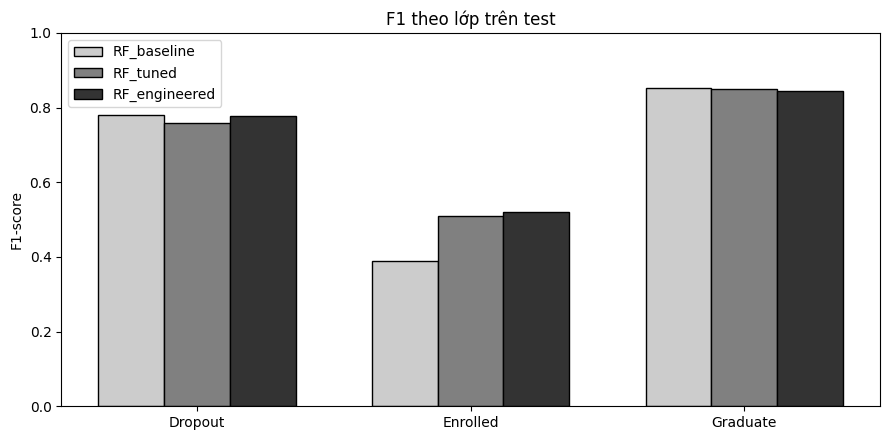

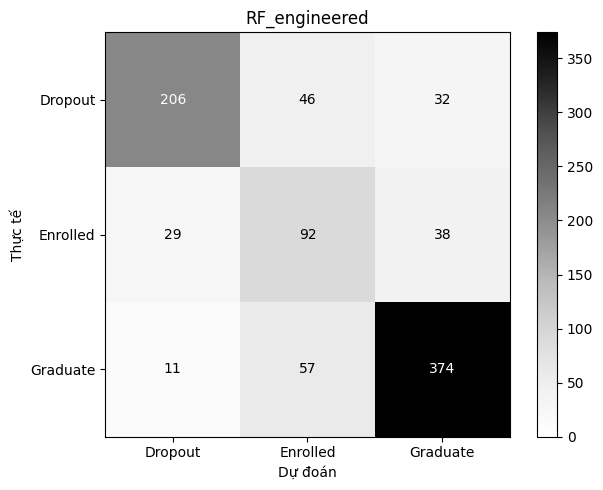

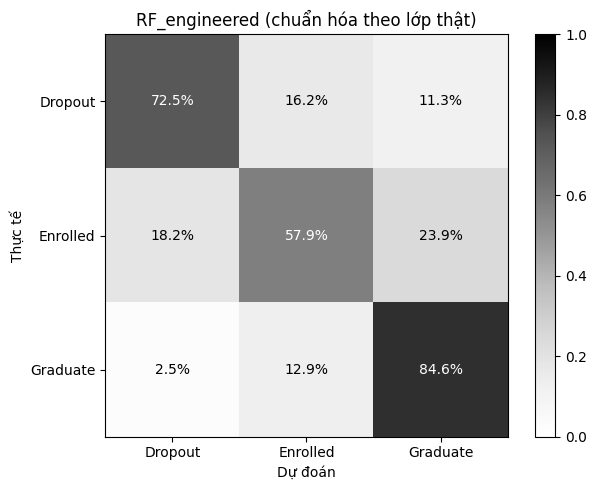

array([[206,  46,  32],
       [ 29,  92,  38],
       [ 11,  57, 374]])

In [20]:
preds={
    'RF_baseline':base.predict(X_test),
    'RF_tuned':tuned.predict(X_test),
    'RF_engineered':engineered.predict(X_test_eng)
}
cv_score_map={'RF_baseline':np.nan,'RF_tuned':original_cv.mean(),'RF_engineered':engineered_cv.mean()}
comparison=pd.DataFrame([
    metric_row(name,y_test,pr,features='full+derived' if name=='RF_engineered' else 'full',
               cv_mean=cv_score_map[name]) for name,pr in preds.items()
])
class_metrics=pd.concat([class_table(n,y_test,p) for n,p in preds.items()],ignore_index=True)
print('Champion by TRAIN CV:',champion_name)
display(comparison.round(4))
display(class_metrics.round(4))

class_f1=class_metrics.pivot(index='class',columns='model',values='f1').reindex(LABELS)
fig,ax=plt.subplots(figsize=(9,4.5))
xs=np.arange(3);width=.24
for k,(label,color) in enumerate([('RF_baseline','0.80'),('RF_tuned','0.50'),('RF_engineered','0.20')]):
    ax.bar(xs+(k-1)*width,class_f1[label],width,color=color,edgecolor='black',label=label)
ax.set(xticks=xs,xticklabels=LABELS,ylim=(0,1),ylabel='F1-score',title='F1 theo lớp trên test')
ax.legend();fig.tight_layout();fig.savefig(OUT/'02_class_f1.png',dpi=150);plt.show()

def draw_cm(name,truth,pred,filename,normalized=False):
    cm=confusion_matrix(truth,pred,labels=LABELS)
    matrix=cm.astype(float)/np.maximum(cm.sum(axis=1,keepdims=True),1) if normalized else cm
    fig,ax=plt.subplots(figsize=(6.4,5))
    im=ax.imshow(matrix,cmap='Greys',vmin=0,vmax=1 if normalized else None)
    ax.set(xticks=np.arange(3),yticks=np.arange(3),xticklabels=LABELS,yticklabels=LABELS,
           xlabel='Dự đoán',ylabel='Thực tế',title=name)
    for (i,j),v in np.ndenumerate(matrix):
        ax.text(j,i,f'{v:.1%}' if normalized else f'{int(v)}',ha='center',va='center',
                color='white' if v>matrix.max()/2 else 'black')
    fig.colorbar(im,ax=ax,fraction=.045)
    fig.tight_layout();fig.savefig(OUT/filename,dpi=150);plt.show()
    return cm
cm_champ=draw_cm(champion_name,y_test,preds[champion_name],'03_champion_confusion.png')
draw_cm(champion_name+' (chuẩn hóa theo lớp thật)',y_test,preds[champion_name],
        '04_champion_confusion_normalized.png',normalized=True)

Errors: 213 / 885
Dropout false negatives: 78 / 284 | FN rate: 0.2746
High-confidence errors (>=0.8): 13


,actual,predicted,count
5,Graduate,Enrolled,57
0,Dropout,Enrolled,46
3,Enrolled,Graduate,38
1,Dropout,Graduate,32
2,Enrolled,Dropout,29
4,Graduate,Dropout,11


,row_index,actual,predicted,confidence,correct,p_Dropout,p_Enrolled,p_Graduate
346,278,Enrolled,Graduate,0.927594,False,0.037047,0.035360,0.927594
374,1987,Enrolled,Dropout,0.912731,False,0.912731,0.083359,0.003909
807,3003,Dropout,Graduate,0.903593,False,0.031223,0.065183,0.903593
801,2117,Dropout,Graduate,0.892768,False,0.042054,0.065178,0.892768
287,1618,Dropout,Graduate,0.877369,False,0.063236,0.059395,0.877369
535,942,Enrolled,Dropout,0.877169,False,0.877169,0.113601,0.009230
582,3891,Enrolled,Graduate,0.853384,False,0.053878,0.092738,0.853384
401,4352,Dropout,Graduate,0.835101,False,0.069474,0.095425,0.835101
256,2716,Enrolled,Dropout,0.825044,False,0.825044,0.160582,0.014374
359,3350,Enrolled,Graduate,0.822315,False,0.062812,0.114873,0.822315


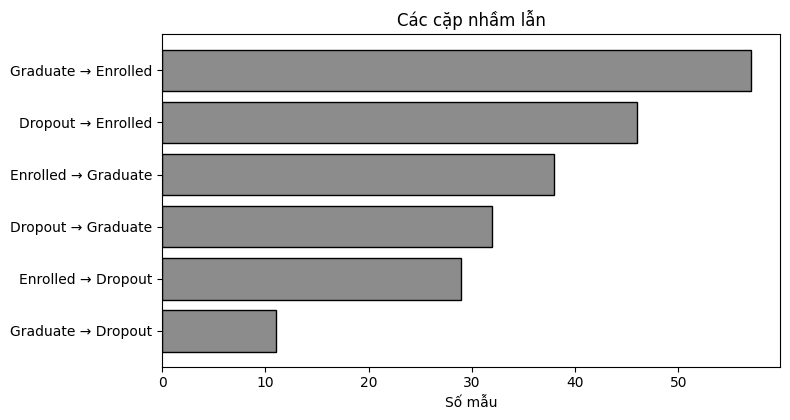

,group,value,n,n_dropout,accuracy,dropout_recall
0,Scholarship holder,0,680,265,0.734,0.743
1,Scholarship holder,1,205,19,0.844,0.474
2,Tuition fees up to date,0,109,93,0.890,0.978
3,Tuition fees up to date,1,776,191,0.741,0.602
4,Age at enrollment,21-24,161,48,0.745,0.708
5,Age at enrollment,<=20,490,107,0.743,0.598
6,Age at enrollment,>=25,234,129,0.803,0.837


In [21]:
proba=champion.predict_proba(test_champion)
classes=list(champion.classes_)
confidence=proba.max(axis=1)
result_test=pd.DataFrame({
    'row_index':X_test.index,'actual':y_test.to_numpy(),'predicted':preds[champion_name],
    'confidence':confidence,'correct':(y_test.to_numpy()==preds[champion_name])
})
for cls in LABELS:
    result_test[f'p_{cls}']=proba[:,classes.index(cls)]
error_pairs=(result_test.loc[~result_test.correct]
             .groupby(['actual','predicted']).size().reset_index(name='count')
             .sort_values('count',ascending=False))
fn_dropout=result_test.loc[(result_test.actual=='Dropout')&(result_test.predicted!='Dropout')].copy()
print('Errors:',int((~result_test.correct).sum()),'/',len(result_test))
print('Dropout false negatives:',len(fn_dropout),'/',int((y_test=='Dropout').sum()),
      '| FN rate:',round(len(fn_dropout)/max(1,int((y_test=='Dropout').sum())),4))
print('High-confidence errors (>=0.8):',int(((~result_test.correct)&(result_test.confidence>=.8)).sum()))
display(error_pairs)
display(result_test.loc[~result_test.correct].sort_values('confidence',ascending=False).head(10))

fig,ax=plt.subplots(figsize=(8,4.3))
z=error_pairs.copy();z['pair']=z['actual']+' → '+z['predicted']
ax.barh(z['pair'].iloc[::-1],z['count'].iloc[::-1],color='0.55',edgecolor='black')
ax.set(xlabel='Số mẫu',title='Các cặp nhầm lẫn')
fig.tight_layout();fig.savefig(OUT/'05_error_pairs.png',dpi=150);plt.show()

def group_table(group_name,values):
    rows=[]
    for val in sorted(pd.Series(values).dropna().unique(),key=str):
        mask=np.asarray(values)==val
        n=int(mask.sum())
        if n<20: continue
        truth=y_test.to_numpy()[mask];pred=preds[champion_name][mask]
        n_d=int((truth=='Dropout').sum())
        rec=(int(((truth=='Dropout')&(pred=='Dropout')).sum())/n_d) if n_d>=10 else np.nan
        rows.append({'group':group_name,'value':val,'n':n,'n_dropout':n_d,
                     'accuracy':accuracy_score(truth,pred),'dropout_recall':rec})
    return pd.DataFrame(rows)

age_bins=pd.cut(X_test['Age at enrollment'],bins=[0,20,24,200],
                labels=['<=20','21-24','>=25'],include_lowest=True)
subgroups=pd.concat([
    group_table('Scholarship holder',X_test['Scholarship holder']),
    group_table('Tuition fees up to date',X_test['Tuition fees up to date']),
    group_table('Age at enrollment',age_bins)
],ignore_index=True)
display(subgroups.round(3))

TRAIN OOF selected threshold: 0.2
TEST: baseline champion / threshold policy


,model,stage,features,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,dropout_precision,dropout_recall,n_test,split_seed,test_fraction,train_cv_f1_macro
2,RF_engineered,holdout,full+derived,0.7593,0.7167,0.7172,0.7167,0.7138,0.7645,0.8374,0.7254,885,42,0.2,0.7209
3,RF_dropout_priority_threshold,holdout,full+derived,0.7175,0.6289,0.6513,0.6289,0.6138,0.6970,0.6176,0.8873,885,42,0.2,NaN


5-bin confidence ECE (diagnostic): 0.0674


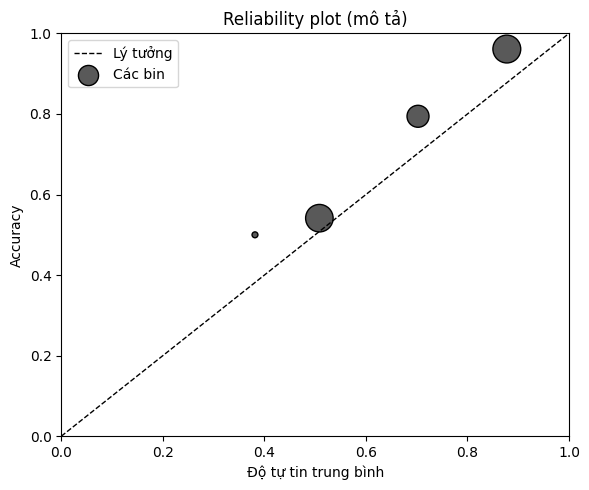

In [22]:
def threshold_dropout(prob,classes,threshold):
    idx=classes.index('Dropout')
    choice=np.argmax(prob,axis=1)
    others=[i for i,c in enumerate(classes) if c!='Dropout']
    fallback=np.array(others)[np.argmax(prob[:,others],axis=1)]
    choice=np.where(prob[:,idx]>=threshold,idx,fallback)
    return np.array(classes)[choice]

oof_prob=cross_val_predict(clone(champion),train_champion,y_train,cv=cv,method='predict_proba',n_jobs=1)
threshold_rows=[]
for t in np.round(np.linspace(.20,.65,10),3):
    op=threshold_dropout(oof_prob,classes,t)
    threshold_rows.append({'threshold':float(t),'dropout_precision':precision_score(y_train,op,labels=['Dropout'],average='macro',zero_division=0),
        'dropout_recall':recall_score(y_train,op,labels=['Dropout'],average='macro',zero_division=0),
        'dropout_f2':fbeta_score(y_train,op,labels=['Dropout'],average='macro',beta=2,zero_division=0),
        'macro_f1':f1_score(y_train,op,average='macro',zero_division=0)})
threshold_cv=pd.DataFrame(threshold_rows).sort_values(['dropout_f2','threshold'],ascending=[False,True])
best_threshold=float(threshold_cv.iloc[0].threshold)
pred_dropout_priority=threshold_dropout(proba,classes,best_threshold)
policy_row=metric_row('RF_dropout_priority_threshold',y_test,pred_dropout_priority,
                      features='full+derived' if champion_name=='RF_engineered' else 'full')
comparison=pd.concat([comparison,pd.DataFrame([policy_row])],ignore_index=True)
class_metrics=pd.concat([class_metrics,class_table('RF_dropout_priority_threshold',y_test,pred_dropout_priority)],ignore_index=True)
print('TRAIN OOF selected threshold:',best_threshold)
print('TEST: baseline champion / threshold policy')
display(comparison[comparison.model.isin([champion_name,'RF_dropout_priority_threshold'])].round(4))

calib=pd.DataFrame({'confidence':confidence,'correct':result_test.correct.astype(int)})
calib['bin']=pd.cut(calib.confidence,np.linspace(0,1,6),include_lowest=True)
calibration=(calib.groupby('bin',observed=False).agg(n=('correct','size'),
                   mean_confidence=('confidence','mean'),accuracy=('correct','mean'))
             .reset_index())
ece=float(np.sum((calibration.n/len(calib))*(calibration.accuracy-calibration.mean_confidence).abs()))
print('5-bin confidence ECE (diagnostic):',round(ece,4))
fig,ax=plt.subplots(figsize=(6,5))
ax.plot([0,1],[0,1],'k--',linewidth=1,label='Lý tưởng')
ax.scatter(calibration.mean_confidence,calibration.accuracy,
           s=np.maximum(15,calibration.n)*1.2,color='0.35',edgecolor='black',label='Các bin')
ax.set(xlim=(0,1),ylim=(0,1),xlabel='Độ tự tin trung bình',ylabel='Accuracy',
       title='Reliability plot (mô tả)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'06_confidence_reliability.png',dpi=150);plt.show()

,seed,n_valid,macro_f1,dropout_recall,accuracy
0,11,885,0.721456,0.750000,0.776271
1,21,885,0.701780,0.764085,0.749153
2,31,885,0.744443,0.760563,0.785311
3,41,885,0.719734,0.725352,0.763842
4,51,885,0.722102,0.760563,0.776271


,macro_f1,dropout_recall,accuracy
mean,0.7219,0.7521,0.7702
std,0.0151,0.0159,0.0140
min,0.7018,0.7254,0.7492
max,0.7444,0.7641,0.7853


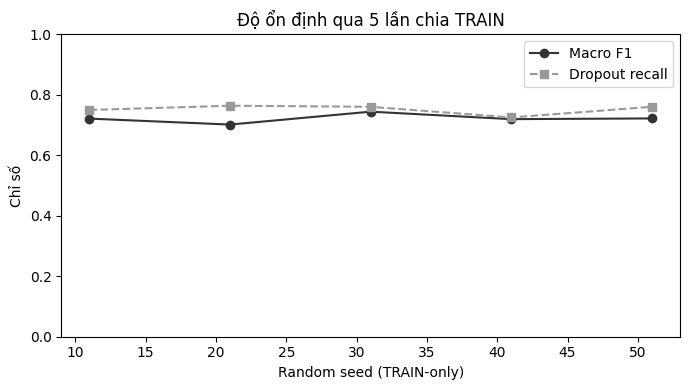

In [23]:
stability_rows=[]
for seed in STABILITY_SEEDS:
    a,b,ya,yb=train_test_split(train_champion,y_train,test_size=.25,stratify=y_train,random_state=seed)
    est=clone(champion);est.set_params(rf__random_state=seed)
    est.fit(a,ya)
    pr=est.predict(b)
    stability_rows.append({'seed':seed,'n_valid':len(yb),
        'macro_f1':f1_score(yb,pr,average='macro',zero_division=0),
        'dropout_recall':recall_score(yb,pr,labels=['Dropout'],average='macro',zero_division=0),
        'accuracy':accuracy_score(yb,pr)})
stability=pd.DataFrame(stability_rows)
stability_summary=stability[['macro_f1','dropout_recall','accuracy']].agg(['mean','std','min','max'])
display(stability)
display(stability_summary.round(4))
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(stability.seed,stability.macro_f1,'o-',color='0.2',label='Macro F1')
ax.plot(stability.seed,stability.dropout_recall,'s--',color='0.6',label='Dropout recall')
ax.set(xlabel='Random seed (TRAIN-only)',ylabel='Chỉ số',ylim=(0,1),
       title='Độ ổn định qua 5 lần chia TRAIN');ax.legend()
fig.tight_layout();fig.savefig(OUT/'07_train_only_stability.png',dpi=150);plt.show()

,feature,permutation_mean,permutation_std,mdi
16,Tuition fees up to date,0.07124,0.00498,0.05360
36,1st_approval_per_enrolled,0.03197,0.00136,0.04482
19,Age at enrollment,0.02924,0.00470,0.02231
18,Scholarship holder,0.02896,0.00073,0.01621
38,1st_not_approved_count,0.02663,0.00423,0.04732
31,Curricular units 2nd sem (grade),0.02622,0.01374,0.05485
13,Displaced,0.02556,0.00284,0.00689
41,2nd_not_approved_count,0.02486,0.00083,0.06688
0,Marital status,0.02467,0.00125,0.00547
40,2nd_approval_per_evaluation,0.02294,0.00866,0.08442


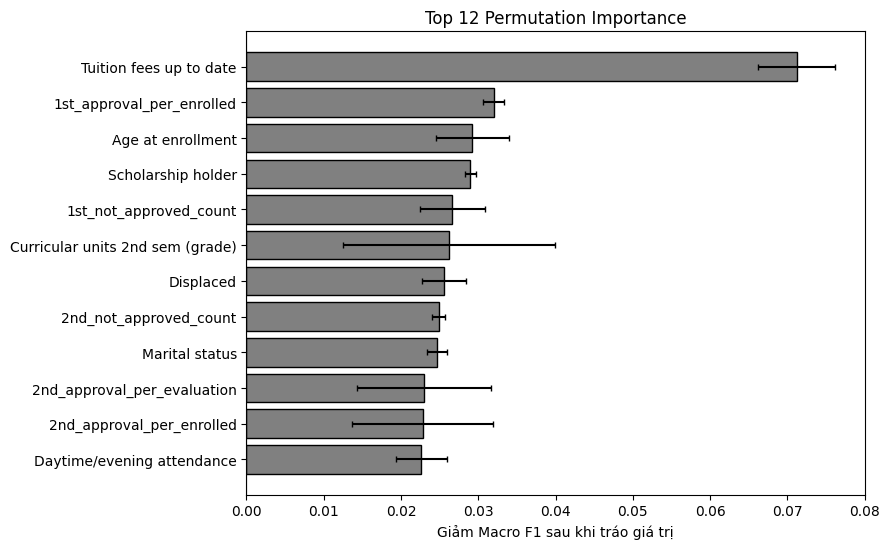

In [24]:
perm=permutation_importance(champion,test_champion,y_test,scoring='f1_macro',
                            n_repeats=PERM_REPEATS,max_samples=PERM_MAX_SAMPLES,random_state=SEED,n_jobs=1)
pr=champion.named_steps['prep'];rf=champion.named_steps['rf']
cat_names=[c for c in train_champion.columns if c in CATEGORICAL]
num_names=[c for c in train_champion.columns if c not in CATEGORICAL]
ohe=pr.named_transformers_['categorical']
original_ohe=[col for col,categories in zip(cat_names,ohe.categories_) for _ in categories]
original_names=original_ohe+num_names
assert len(original_names)==len(rf.feature_importances_)
mdi=pd.DataFrame({'feature':original_names,'mdi':rf.feature_importances_}).groupby('feature',as_index=False).sum()
importance=(pd.DataFrame({'feature':train_champion.columns,
                          'permutation_mean':perm.importances_mean,
                          'permutation_std':perm.importances_std})
            .merge(mdi,on='feature',how='left')
            .sort_values('permutation_mean',ascending=False))
display(importance.head(15).round(5))
fig,ax=plt.subplots(figsize=(9,5.6))
top=importance.head(12).iloc[::-1]
ax.barh(top.feature,top.permutation_mean,xerr=top.permutation_std,
        color='0.5',edgecolor='black',capsize=2)
ax.axvline(0,color='black',lw=.8)
ax.set(xlabel='Giảm Macro F1 sau khi tráo giá trị',title='Top 12 Permutation Importance')
fig.tight_layout();fig.savefig(OUT/'08_feature_importance.png',dpi=150);plt.show()

,model,accuracy,f1_macro,dropout_recall
2,RF_engineered,0.7593,0.7138,0.7254
4,RF_at_enrollment,0.5876,0.5498,0.5951
5,RF_after_sem1,0.7119,0.6597,0.6866


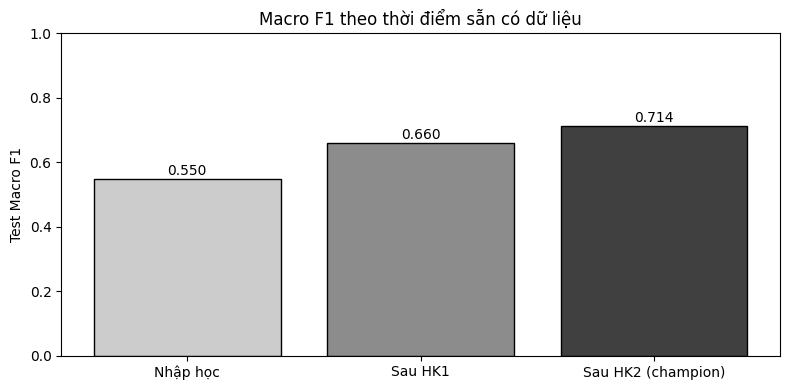

In [25]:
EARLY=[c for c in X.columns if not c.startswith('Curricular units 1st sem')
       and not c.startswith('Curricular units 2nd sem')]
AFTER_1=[c for c in X.columns if not c.startswith('Curricular units 2nd sem')]
scenario_rows=[]
for name,cols in [('RF_at_enrollment',EARLY),('RF_after_sem1',AFTER_1)]:
    model=pipe(cols)
    model.set_params(**search.best_params_)
    model.fit(X_train[cols],y_train)
    pred=model.predict(X_test[cols])
    scenario_rows.append(metric_row(name,y_test,pred,stage='scenario',features=name))
    class_metrics=pd.concat([class_metrics,class_table(name,y_test,pred)],ignore_index=True)
comparison=pd.concat([comparison,pd.DataFrame(scenario_rows)],ignore_index=True)
scenario_compare=comparison.loc[comparison.model.isin(['RF_at_enrollment','RF_after_sem1',champion_name]),
                              ['model','accuracy','f1_macro','dropout_recall']].drop_duplicates('model')
display(scenario_compare.round(4))
fig,ax=plt.subplots(figsize=(8,4))
labels=['Nhập học','Sau HK1','Sau HK2 (champion)']
vals=[comparison.loc[comparison.model=='RF_at_enrollment','f1_macro'].iloc[0],
      comparison.loc[comparison.model=='RF_after_sem1','f1_macro'].iloc[0],
      comparison.loc[comparison.model==champion_name,'f1_macro'].iloc[0]]
bars=ax.bar(labels,vals,color=['0.8','0.55','0.25'],edgecolor='black')
for b,v in zip(bars,vals):ax.text(b.get_x()+b.get_width()/2,v+.012,f'{v:.3f}',ha='center')
ax.set(ylabel='Test Macro F1',ylim=(0,1),title='Macro F1 theo thời điểm sẵn có dữ liệu')
fig.tight_layout();fig.savefig(OUT/'09_feature_timing_ablation.png',dpi=150);plt.show()

In [26]:
# CSV chuẩn để nhóm ghép theo cùng split
comparison.to_csv(OUT/'experiment_log.csv',index=False,encoding='utf-8-sig')
class_metrics.to_csv(OUT/'class_metrics.csv',index=False,encoding='utf-8-sig')
cv_results[['rank_test_score','mean_test_score','std_test_score','mean_train_score','params']].to_csv(
    OUT/'tuning_cv_results.csv',index=False,encoding='utf-8-sig')
selection.to_csv(OUT/'candidate_selection.csv',index=False,encoding='utf-8-sig')
error_pairs.to_csv(OUT/'error_pairs.csv',index=False,encoding='utf-8-sig')
result_test.to_csv(OUT/'test_predictions.csv',index=False,encoding='utf-8-sig')
fn_dropout.to_csv(OUT/'dropout_false_negatives.csv',index=False,encoding='utf-8-sig')
subgroups.to_csv(OUT/'subgroup_analysis.csv',index=False,encoding='utf-8-sig')
threshold_cv.to_csv(OUT/'threshold_train_oof.csv',index=False,encoding='utf-8-sig')
calibration.to_csv(OUT/'calibration_bins.csv',index=False,encoding='utf-8-sig')
stability.to_csv(OUT/'stability_train_only.csv',index=False,encoding='utf-8-sig')
importance.to_csv(OUT/'feature_importance.csv',index=False,encoding='utf-8-sig')
counts.rename_axis('class').reset_index(name='count').to_csv(
    OUT/'class_distribution.csv',index=False,encoding='utf-8-sig')
comparison[['model','accuracy','balanced_accuracy','precision_macro','recall_macro','f1_macro',
            'f1_weighted','dropout_recall','n_test','split_seed','test_fraction','train_cv_f1_macro']].to_csv(
    OUT/'group_comparison_template.csv',index=False,encoding='utf-8-sig')

rr=comparison.set_index('model')
main=rr.loc[champion_name]
f1cm=class_metrics.loc[class_metrics.model==champion_name].set_index('class')
summary={
    'source':data_source,'dataset_sha256':source_sha,'n_rows':len(df),'n_features_raw':X.shape[1],
    'class_counts':{k:int(v) for k,v in counts.items()},
    'train_size':len(X_train),'test_size':len(X_test),'seed':SEED,
    'cv_folds':3,'tuning_iterations':N_ITER,'tuning_cv_fits':N_ITER*3,
    'best_cv_f1':float(search.best_score_),'best_params':search.best_params_,
    'champion_name':champion_name,'candidate_cv':selection.to_dict(orient='records'),
    'holdout_results':comparison.to_dict(orient='records'),
    'champion_class_metrics':f1cm.reset_index().to_dict(orient='records'),
    'champion_confusion_matrix':cm_champ.tolist(),'error_pairs':error_pairs.to_dict(orient='records'),
    'n_errors':int((~result_test.correct).sum()),'dropout_fn':len(fn_dropout),
    'dropout_fn_rate':float(len(fn_dropout)/max(1,int((y_test=='Dropout').sum()))),
    'high_confidence_errors':int(((~result_test.correct)&(result_test.confidence>=.8)).sum()),
    'selected_dropout_threshold_train_oof':best_threshold,'ece_5_bins_diagnostic':ece,
    'stability_mean_macro_f1':float(stability.macro_f1.mean()),
    'stability_std_macro_f1':float(stability.macro_f1.std(ddof=1)),
    'top_features_permutation':importance.head(10).feature.tolist()
}
(OUT/'report_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
notes=f"""# RANDOM FOREST NÂNG CAO — GỢI Ý VIẾT BÁO CÁO

## 2.4. Thuật toán / nguyên lý
Random Forest là thuật toán ensemble gồm nhiều cây quyết định huấn luyện trên các mẫu bootstrap;
khi phân chia nút chỉ xét tập con đặc trưng. RF tổng hợp phiếu của các cây để phân lớp.
Bài toán có 3 nhãn Dropout, Enrolled, Graduate. One-Hot Encoding đặt trong Pipeline và fit
trong từng fold tránh leakage từ quá trình biến đổi. Các mã số danh mục không được xem là đại lượng liên tục.

## 4.3. Thiết lập thực nghiệm
Dữ liệu: {len(df)} bản ghi, {X.shape[1]} biến đầu vào; train={len(X_train)} và test={len(X_test)},
stratified 80:20, random_state=42. Tuning: {N_ITER} bộ tham số × 3-fold = {N_ITER*3} lượt CV;
chọn theo Macro F1 trên TRAIN (CV tốt nhất={search.best_score_:.4f}).
Tham số: {json.dumps(search.best_params_,ensure_ascii=False,default=str)}.
Kiểm tra candidate tuned và thêm các chỉ số tỷ lệ học phần; lựa chọn bằng TRAIN-CV.
Champion: {champion_name}.

## 4.4. So sánh và bảng log
RF baseline Macro F1={rr.loc['RF_baseline','f1_macro']:.4f},
RF tuned={rr.loc['RF_tuned','f1_macro']:.4f},
RF engineered={rr.loc['RF_engineered','f1_macro']:.4f} trên cùng holdout.
Chỉ so sánh các mô hình của thành viên khác nếu dùng cùng test_indices.csv, split_seed và quy trình tương đương.

## 4.5. Phân tích lỗi
Champion: Accuracy={main.accuracy:.4f}, Macro F1={main.f1_macro:.4f},
Balanced Accuracy={main.balanced_accuracy:.4f}; số mẫu sai={summary['n_errors']}/{len(X_test)}.
Dropout Precision={f1cm.loc['Dropout','precision']:.4f}, Recall={f1cm.loc['Dropout','recall']:.4f},
F1={f1cm.loc['Dropout','f1']:.4f}. Dropout false negatives={len(fn_dropout)}
({summary['dropout_fn_rate']:.1%} trong các mẫu Dropout thực tế).
Enrolled F1={f1cm.loc['Enrolled','f1']:.4f}; Graduate F1={f1cm.loc['Graduate','f1']:.4f}.
Ma trận nhầm lẫn [thực tế × dự đoán] theo Dropout/Enrolled/Graduate: {cm_champ.tolist()}.
Các cặp nhầm xem error_pairs.csv. Số lỗi độ tự tin >= 0.8:
{summary['high_confidence_errors']}. ECE mô tả 5 bins={ece:.4f}, không phải hiệu chuẩn xác suất.
Ngưỡng ưu tiên Dropout được chọn từ OOF TRAIN: t={best_threshold:.3f},
nghiệm pháp đánh đổi precision/recall; không xem là cấu hình thay thế mặc định.
Độ ổn định TRAIN-only ({len(stability)} seed): Macro F1 trung bình={stability.macro_f1.mean():.4f},
độ lệch chuẩn={stability.macro_f1.std(ddof=1):.4f}.
Permutation importance cao nhất: {', '.join(importance.head(5).feature.tolist())}.

## Chương 5. Hạn chế và hướng tiếp theo
Không dùng Accuracy đơn lẻ vì lớp Enrolled ít mẫu. Dữ liệu học kỳ 2 có thể khiến bài toán
khác hẳn dự đoán từ ngày nhập học. Biến học phần và tình trạng học phí có thể là thông tin
đến sau khi sinh viên đã bắt đầu học. Các biến quan trọng phản ánh liên hệ dự đoán, không là nhân quả.
Dữ liệu thuộc một bối cảnh giáo dục cụ thể; cần kiểm thử theo năm học/trường khác, đánh giá
calibration & fairness với thiết kế được phê duyệt; cân nhắc phương án mô hình từng giai đoạn
và kiểm tra drift, sai lệch dữ liệu, chính sách bảo mật trước ứng dụng.

## Chương 6. Đóng góp / khó khăn / kế hoạch — BẮT BUỘC ĐIỀN THEO THỰC TẾ
- Đã thực hiện (gắn link notebook, log, ảnh kết quả): [tự điền]
- Khó khăn có minh chứng: [tự điền]
- Cách khắc phục và bài học: [tự điền]
- Đầu việc còn lại / ngày bàn giao: [tự điền]
- Kiểm tra chéo cùng thành viên nào, kết quả: [tự điền]
"""
(OUT/'RF_advanced_report_notes_vi.md').write_text(notes,encoding='utf-8')
manifest={'scikit_learn':SKLEARN_VERSION,'seed':SEED,'fast_mode':FAST_MODE,
          'data_source':data_source,'data_sha256':source_sha,
          'same_test_indices_file':'test_indices.csv', 'results_champion':champion_name,
          'caution':'Các kịch bản thời điểm dữ liệu không thể so sánh trực tiếp như cùng thông tin.'}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')

archive=ROOT/'RF_Advanced_Outputs.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as zz:
    for path in sorted(OUT.glob('*')):
        if path.is_file():zz.write(path,arcname=path.name)
print('DONE. Output zip:',archive)
print('Output files:',len(list(OUT.glob('*'))))

DONE. Output zip: /kaggle/working/RF_Advanced_Outputs.zip
Output files: 27


### 4.3.2 - So sánh F1 ba mô hình RF

**Tên file: `02_class_f1.png`**

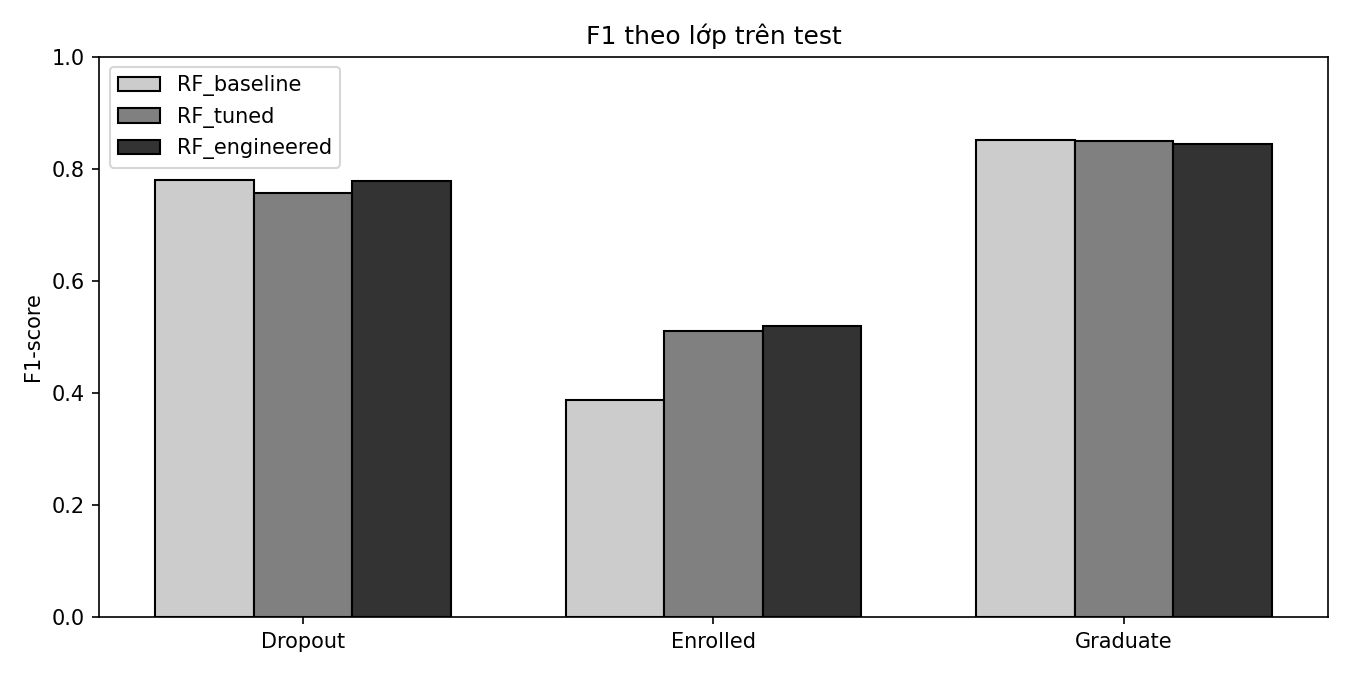

### 4.3.3 - Tầm quan trọng đặc trưng

**Tên file: `08_feature_importance.png`**

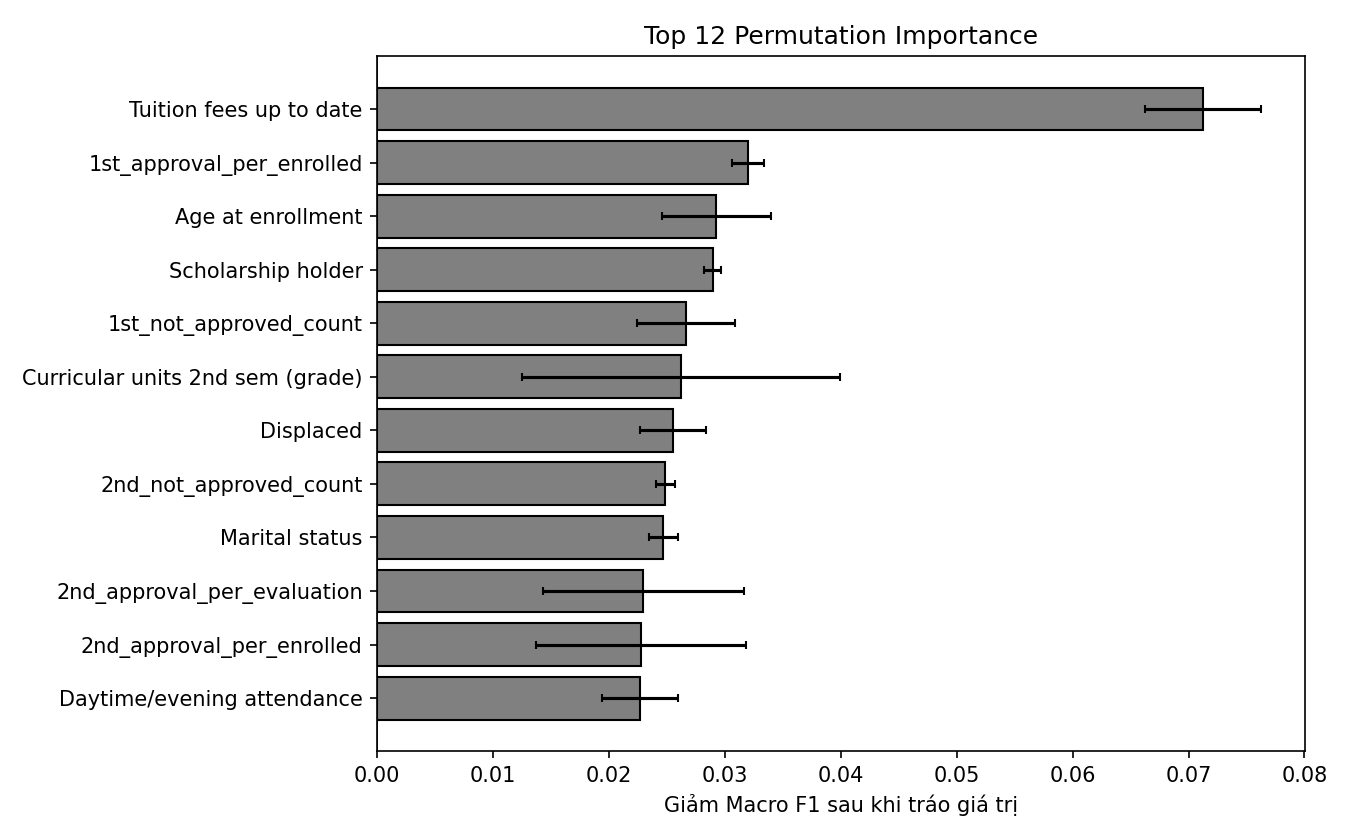

### 4.5.2 - Ma trận nhầm lẫn

**Tên file: `03_champion_confusion.png`**

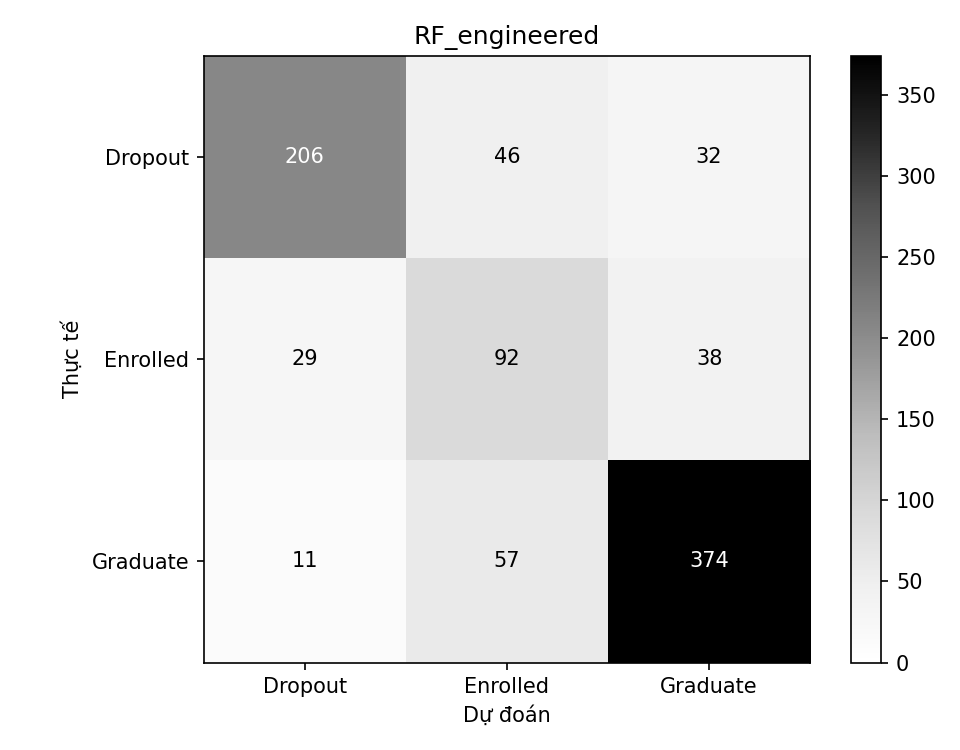

### 4.5.2 - Các cặp dự đoán sai

**Tên file: `05_error_pairs.png`**

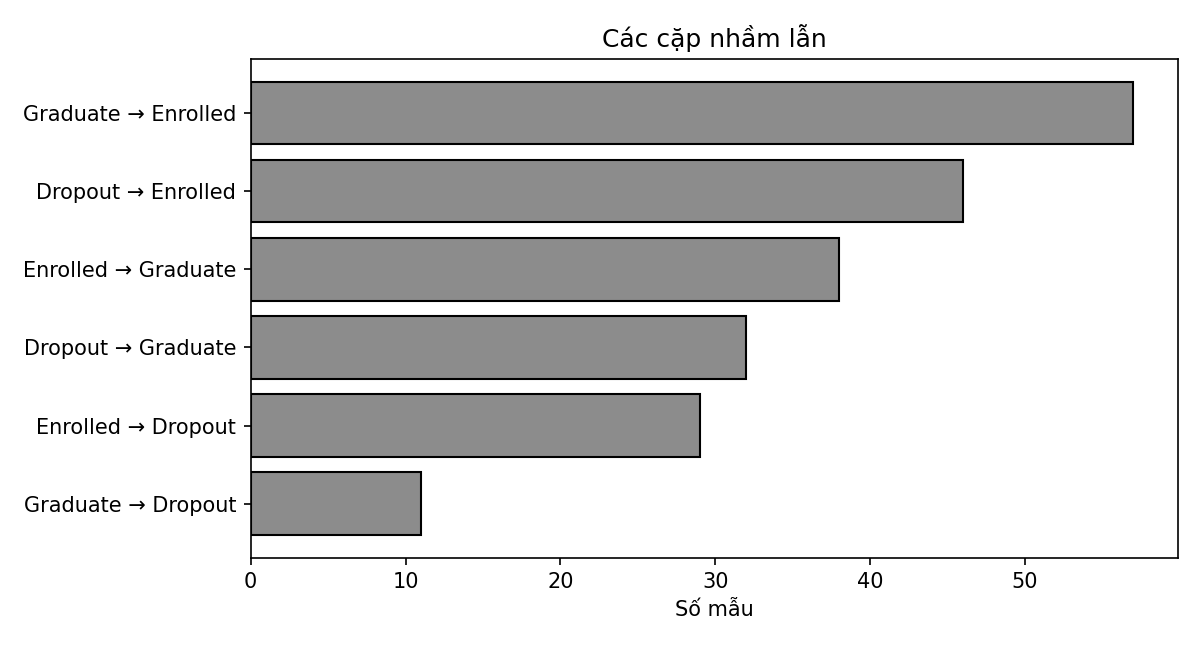

### 4.5.2 - Độ ổn định qua 5 lần chia

**Tên file: `07_train_only_stability.png`**

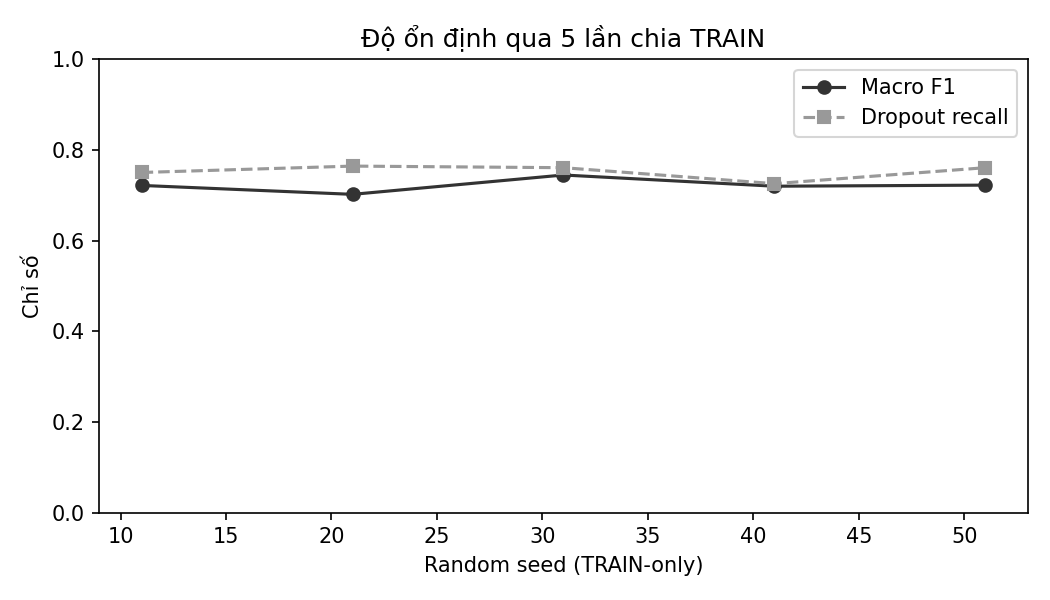

### 5.3 - So sánh thời điểm dự đoán (bổ sung)

**Tên file: `09_feature_timing_ablation.png`**

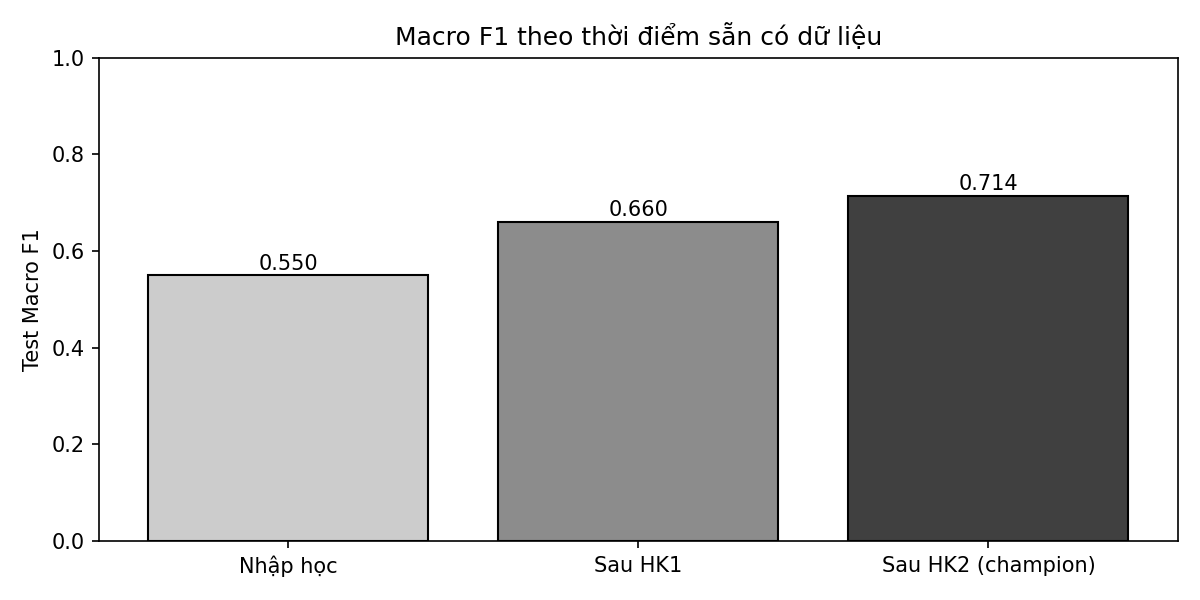

In [27]:

from pathlib import Path
from IPython.display import display, Image, Markdown

OUT = Path("/kaggle/working/RF_Advanced_Outputs")

HINH_BAO_CAO = [
    ("4.3.2 - So sánh F1 ba mô hình RF", "02_class_f1.png"),
    ("4.3.3 - Tầm quan trọng đặc trưng", "08_feature_importance.png"),
    ("4.5.2 - Ma trận nhầm lẫn", "03_champion_confusion.png"),
    ("4.5.2 - Các cặp dự đoán sai", "05_error_pairs.png"),
    ("4.5.2 - Độ ổn định qua 5 lần chia", "07_train_only_stability.png"),
    ("5.3 - So sánh thời điểm dự đoán (bổ sung)", "09_feature_timing_ablation.png"),
]

if not OUT.is_dir():
    print("Chưa có thư mục kết quả. Hãy chạy Run All trước.")
else:
    for ten, file in HINH_BAO_CAO:
        display(Markdown(f"### {ten}"))
        display(Markdown(f"**Tên file: `{file}`**"))
        path = OUT / file
        if path.exists():
            display(Image(filename=str(path), width=750))
        else:
            print("Chưa tìm thấy:", path)


### 4.5.2 - Các cặp nhầm lẫn

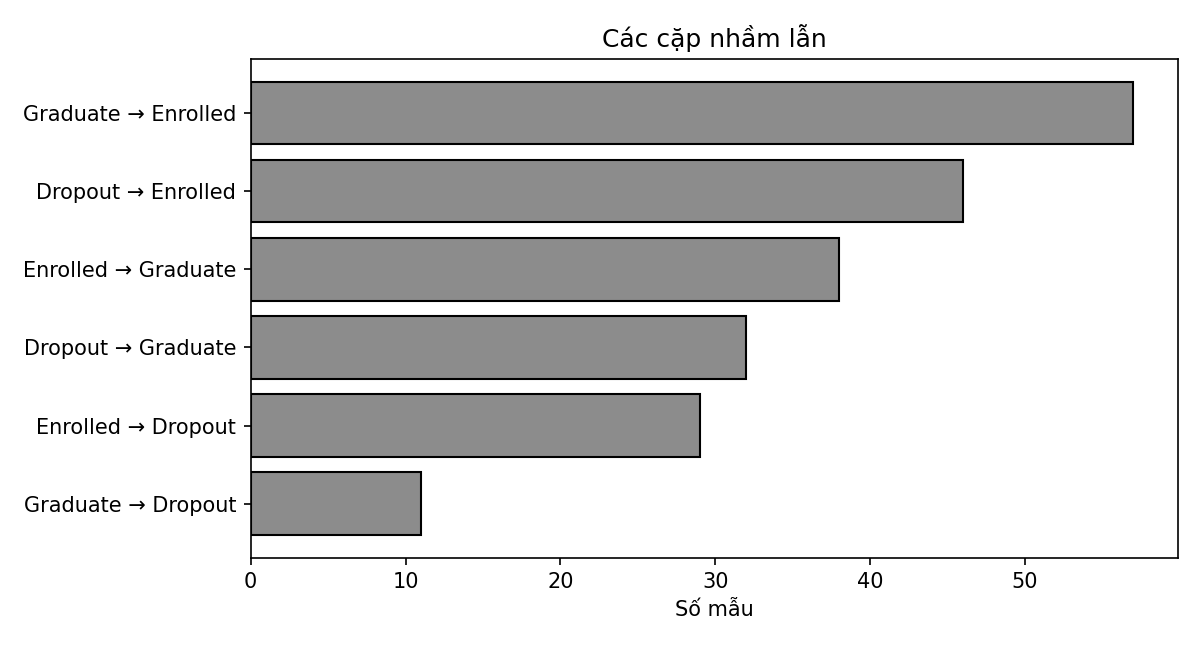

### 4.5.2 - Độ ổn định

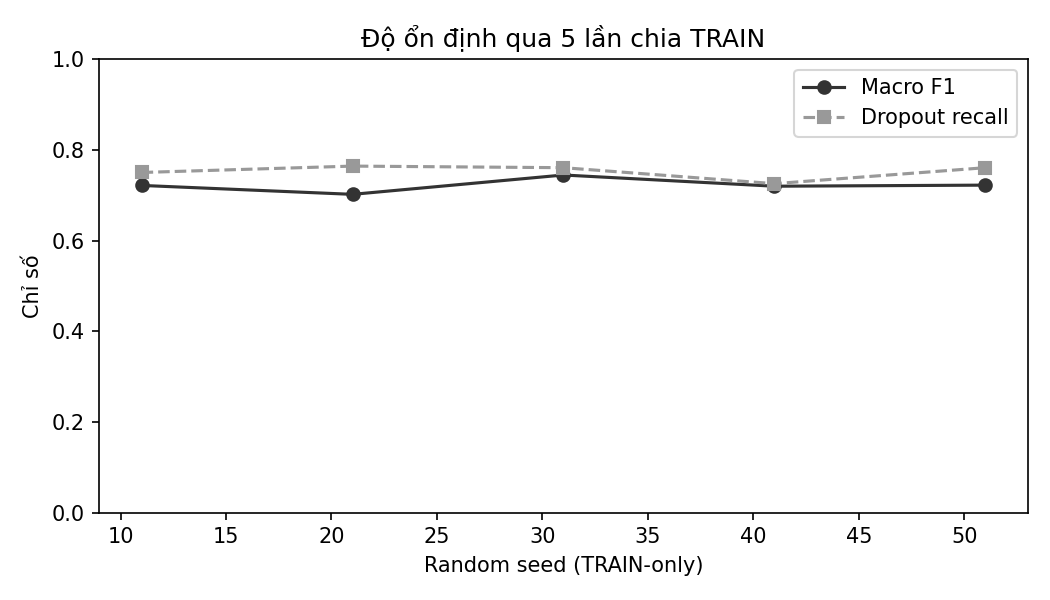

### 5.3 - Thời điểm dự đoán

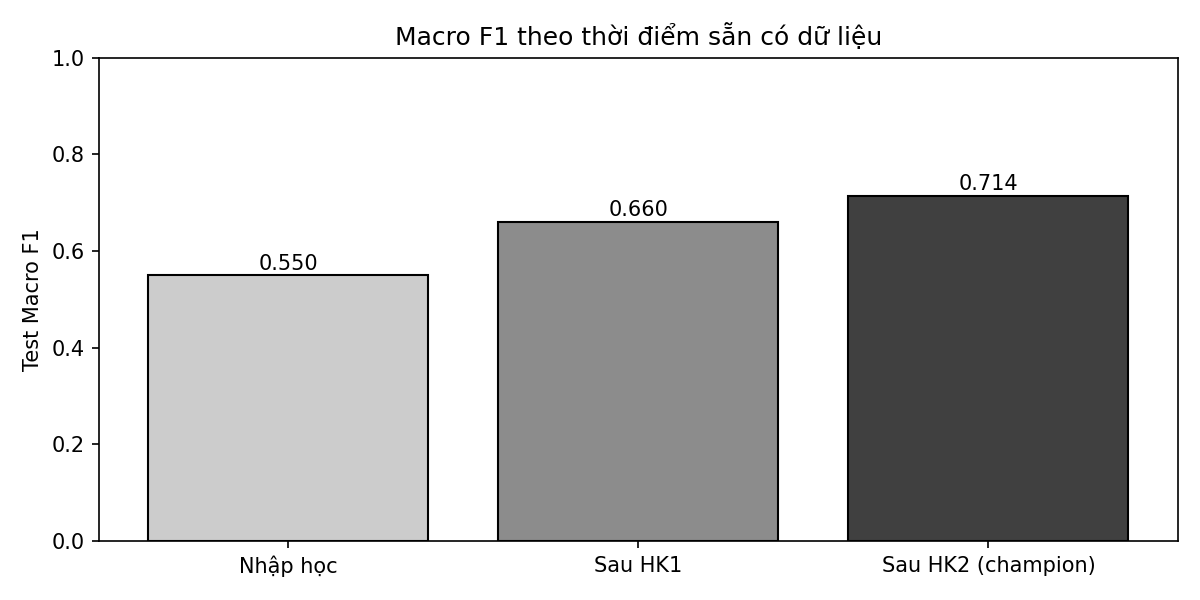

### 4.5.2 - Overfitting

Train Macro-F1: 0.8805
Validation Macro-F1: 0.7103
Gap: 0.1702


### 4.5.2 - Điều chỉnh ngưỡng Dropout

,model,dropout_precision,dropout_recall,f1_macro
2,RF_engineered,0.8374,0.7254,0.7138
3,RF_dropout_priority_threshold,0.6176,0.8873,0.6138


### 6.1 - Minh chứng kết quả

Số file đầu ra: 27
Các file:
01_class_distribution.png
02_class_f1.png
03_champion_confusion.png
04_champion_confusion_normalized.png
05_error_pairs.png
06_confidence_reliability.png
07_train_only_stability.png
08_feature_importance.png
09_feature_timing_ablation.png
RF_advanced_report_notes_vi.md
calibration_bins.csv
candidate_selection.csv
class_distribution.csv
class_metrics.csv
dropout_false_negatives.csv
error_pairs.csv
experiment_log.csv
feature_importance.csv
group_comparison_template.csv
report_summary.json
run_manifest.json
stability_train_only.csv
subgroup_analysis.csv
test_indices.csv
test_predictions.csv
threshold_train_oof.csv
tuning_cv_results.csv


In [28]:

from pathlib import Path
from IPython.display import display, Image, Markdown
import pandas as pd

OUT = Path("/kaggle/working/RF_Advanced_Outputs")

HINH = [
    ("4.5.2 - Các cặp nhầm lẫn", "05_error_pairs.png"),
    ("4.5.2 - Độ ổn định", "07_train_only_stability.png"),
    ("5.3 - Thời điểm dự đoán", "09_feature_timing_ablation.png"),
]

for ten, filename in HINH:
    display(Markdown(f"### {ten}"))
    path = OUT / filename
    if path.exists():
        display(Image(filename=str(path), width=800))
    else:
        print("Chưa có:", filename)

display(Markdown("### 4.5.2 - Overfitting"))
cv = pd.read_csv(OUT / "tuning_cv_results.csv")
best = cv.sort_values("rank_test_score").iloc[0]
print("Train Macro-F1:", round(best.mean_train_score, 4))
print("Validation Macro-F1:", round(best.mean_test_score, 4))
print("Gap:", round(best.mean_train_score - best.mean_test_score, 4))

display(Markdown("### 4.5.2 - Điều chỉnh ngưỡng Dropout"))
log = pd.read_csv(OUT / "experiment_log.csv")
display(log[
    log["model"].isin([
        "RF_engineered",
        "RF_dropout_priority_threshold"
    ])
][["model", "dropout_precision", "dropout_recall", "f1_macro"]].round(4))

display(Markdown("### 6.1 - Minh chứng kết quả"))
print("Số file đầu ra:", len(list(OUT.iterdir())))
print("Các file:")
for p in sorted(OUT.iterdir()):
    if p.is_file():
        print(p.name)
